In [1]:
# Destino del dataset
carpeta_destino <- "/home/ds/buckets/b1/datasets"
archivo <- file.path(carpeta_destino, "competencia_01_crudo.csv")

# Descargar solo si todavía no existe
if (!file.exists(archivo)) {
  download.file(
    url = paste0(
      "https://storage.googleapis.com/open-courses/",
      "dmeyf2026-9c6f/competencia_01_crudo.csv"
    ),
    destfile = archivo,
    method = "libcurl",
    mode = "wb"
  )
}

cat("Dataset guardado en:", archivo, "\n")

Dataset guardado en: /home/ds/buckets/b1/datasets/competencia_01_crudo.csv 


In [2]:
#Clase Ternaria

require( "data.table" )

# leo el dataset
dataset <- fread("/home/ds/buckets/b1/datasets/competencia_01_crudo.csv" )

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]


# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1


# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]


# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




In [3]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


In [4]:
# Mayo 2021: reemplazar por NA porque no hubo actualizaciones
dataset[foto_mes == 202105, ccajas_depositos := NA]

In [5]:
# ============================================================
# PATRIMONIO NETO: Activos - Pasivos
# ============================================================

activos <- c(
  "mcuentas_saldo",
  "mplazo_fijo_pesos",
  "mplazo_fijo_dolares",
  "minversion1_pesos",
  "minversion1_dolares",
  "minversion2"
)

pasivos <- c(
  "mprestamos_personales",
  "mprestamos_prendarios",
  "mprestamos_hipotecarios",
  "Master_msaldototal",
  "Visa_msaldototal"
)

# Solo usar variables que existan en el dataset
activos <- intersect(activos, names(dataset))
pasivos <- intersect(pasivos, names(dataset))

# Crear agregados conservando los faltantes
dataset[, Activos_totales := rowSums(.SD, na.rm = FALSE),
        .SDcols = activos]

dataset[, Pasivos_totales := rowSums(.SD, na.rm = FALSE),
        .SDcols = pasivos]

# Patrimonio neto
dataset[, Patrimonio_neto := Activos_totales - Pasivos_totales]

In [6]:
dim(dataset)

[1] 983061    158

In [7]:
library(data.table)
setDT(dataset)

# Verificar identificadores
if (anyNA(dataset$numero_de_cliente) || anyNA(dataset$foto_mes)) {
  stop("Hay valores faltantes en numero_de_cliente o foto_mes.")
}

# Verificar que haya una sola fila por cliente y mes
if (anyDuplicated(dataset[, .(numero_de_cliente, foto_mes)])) {
  stop("Hay registros duplicados por cliente y mes.")
}

setorder(dataset, numero_de_cliente, foto_mes)

# Variables originales: excluir auxiliares y columnas ya generadas
columnas <- names(dataset)[vapply(dataset, is.numeric, logical(1))]

columnas <- setdiff(
  columnas,
  c(
    "numero_de_cliente", "foto_mes", "clase_ternaria",
    ".mes_aux", ".mes_lag1", ".mes_lag2"
  )
)

columnas <- columnas[!grepl("^(Lag[12]_|Delta[12]_)", columnas)]

if (!length(columnas)) {
  stop("No hay variables numéricas para crear lags y deltas.")
}

# Índice mensual consecutivo
mes <- (dataset$foto_mes %/% 100L) * 12L +
  dataset$foto_mes %% 100L

# Tabla pequeña para localizar cada registro por cliente y mes
indice <- data.table(
  numero_de_cliente = dataset$numero_de_cliente,
  mes_idx = mes,
  fila = seq_len(nrow(dataset))
)

# Mes anterior exacto de cada registro
consulta <- data.table(
  numero_de_cliente = dataset$numero_de_cliente,
  mes_idx = mes - 1L
)

idx1 <- indice[
  consulta,
  on = .(numero_de_cliente, mes_idx),
  fila
]

# Dos meses atrás exactos, aunque falte el mes intermedio
consulta[, mes_idx := mes - 2L]

idx2 <- indice[
  consulta,
  on = .(numero_de_cliente, mes_idx),
  fila
]

# Si no existe el mes buscado, el índice queda en NA
stopifnot(
  length(idx1) == nrow(dataset),
  length(idx2) == nrow(dataset)
)

rm(indice, consulta, mes)
gc()

# Crear columnas sin volver a agrupar por cliente
for (i in seq_along(columnas)) {

  col <- columnas[i]
  actual <- as.numeric(dataset[[col]])

  lag1 <- actual[idx1]
  lag2 <- actual[idx2]

  set(dataset, j = paste0("Lag1_", col), value = lag1)
  set(dataset, j = paste0("Lag2_", col), value = lag2)
  set(dataset, j = paste0("Delta1_", col), value = actual - lag1)
  set(dataset, j = paste0("Delta2_", col), value = actual - lag2)

  cat(i, "de", length(columnas), "-", col, "\n")
  flush.console()
}

# Limpiar auxiliares que pudiera dejar una ejecución anterior
auxiliares <- intersect(
  names(dataset),
  c(".mes_aux", ".mes_lag1", ".mes_lag2")
)

if (length(auxiliares)) {
  dataset[, (auxiliares) := NULL]
}

rm(idx1, idx2, actual, lag1, lag2)
gc()

dim(dataset)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,751027,40.2,1479661,79.1,1479661,79.1
Vcells,123809597,944.6,213575024,1629.5,212616194,1622.2


1 de 155 - active_quarter 
2 de 155 - cliente_vip 
3 de 155 - internet 
4 de 155 - cliente_edad 
5 de 155 - cliente_antiguedad 
6 de 155 - mrentabilidad 
7 de 155 - mrentabilidad_annual 
8 de 155 - mcomisiones 
9 de 155 - mactivos_margen 
10 de 155 - mpasivos_margen 
11 de 155 - cproductos 
12 de 155 - tcuentas 
13 de 155 - ccuenta_corriente 
14 de 155 - mcuenta_corriente_adicional 
15 de 155 - mcuenta_corriente 
16 de 155 - ccaja_ahorro 
17 de 155 - mcaja_ahorro 
18 de 155 - mcaja_ahorro_adicional 
19 de 155 - mcaja_ahorro_dolares 
20 de 155 - cdescubierto_preacordado 
21 de 155 - mcuentas_saldo 
22 de 155 - ctarjeta_debito 
23 de 155 - ctarjeta_debito_transacciones 
24 de 155 - mautoservicio 
25 de 155 - ctarjeta_visa 
26 de 155 - ctarjeta_visa_transacciones 
27 de 155 - mtarjeta_visa_consumo 
28 de 155 - ctarjeta_master 
29 de 155 - ctarjeta_master_transacciones 
30 de 155 - mtarjeta_master_consumo 
31 de 155 - cprestamos_personales 
32 de 155 - mprestamos_personales 
33 de 155 - cp

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,753789,40.3,1479661,79.1,1479661,79.1
Vcells,732330937,5587.3,919653428,7016.4,765996083,5844.1


[1] 983061    778

In [8]:
# Tipo de cada columna
table(vapply(dataset, function(x) class(x)[1], character(1)))

# Cantidad de columnas nuevas por tipo
sapply(c("Lag1_", "Lag2_", "Delta1_", "Delta2_"), function(prefijo) {
  sum(startsWith(names(dataset), prefijo))
})


character   integer   numeric 
        1        80       697 

Lag1_   Lag2_ Delta1_ Delta2_ 
    155     155     155     155

In [9]:
library(data.table)
library(Rcpp)

setDT(dataset)
setorder(dataset, numero_de_cliente, foto_mes)

# Ventana: mes actual + los 2 meses anteriores
VENTANA_HISTORIA <- 3L

# Solo variables originales numéricas
# Excluir ID, mes, clase, auxiliares y variables ya generadas
cols_lagueables <- names(dataset)[
  vapply(dataset, is.numeric, logical(1))
]

cols_lagueables <- setdiff(
  cols_lagueables,
  c(
    "numero_de_cliente", "foto_mes", "clase_ternaria",
    ".mes_aux", ".mes_lag1", ".mes_lag2"
  )
)

cols_lagueables <- cols_lagueables[
  !grepl(
    "^(Lag[12]_|Delta[12]_|rank_|missing_|las_zero_)",
    cols_lagueables
  ) &
  !grepl(
    "_(tend|min|max|avg|ratioavg|ratiomax)[0-9]+$",
    cols_lagueables
  )
]

# Validaciones
stopifnot(
  nrow(dataset) > 0L,
  !anyNA(dataset$numero_de_cliente),
  !anyNA(dataset$foto_mes),
  VENTANA_HISTORIA >= 2L
)

if (anyDuplicated(dataset[, .(numero_de_cliente, foto_mes)])) {
  stop("Hay registros duplicados por cliente y mes.")
}

# Índice mensual: conserva las distancias reales entre meses
mes_hist <- as.integer(
  (dataset$foto_mes %/% 100L) * 12L +
    dataset$foto_mes %% 100L
)

# Identificador consecutivo de cada cliente, con datos ordenados
grupo_hist <- as.integer(rleid(dataset$numero_de_cliente))

# Tendencia por mínimos cuadrados y promedio
# Solo usa el mes actual y meses anteriores dentro de la ventana
cppFunction('
Rcpp::List fhist_tend_avg(
    Rcpp::NumericVector valores,
    Rcpp::IntegerVector meses,
    Rcpp::IntegerVector grupos,
    int ventana) {

  int n = valores.size();

  Rcpp::NumericVector tendencia(n, NA_REAL);
  Rcpp::NumericVector promedio(n, NA_REAL);

  for (int i = 0; i < n; i++) {

    if (i % 10000 == 0) Rcpp::checkUserInterrupt();

    int cantidad = 0;
    double sx = 0.0;
    double sy = 0.0;
    double sxx = 0.0;
    double sxy = 0.0;

    int mes_desde = meses[i] - ventana + 1;

    for (int j = i; j >= 0; j--) {

      if (grupos[j] != grupos[i]) break;
      if (meses[j] < mes_desde) break;

      double y = valores[j];

      // Excluir NA, NaN e infinitos
      if (!R_FINITE(y)) continue;

      // Distancia mensual respecto al mes actual
      double x = meses[j] - meses[i];

      cantidad++;
      sx += x;
      sy += y;
      sxx += x * x;
      sxy += x * y;
    }

    if (cantidad >= 2) {

      double denominador =
        cantidad * sxx - sx * sx;

      if (denominador > 0.0) {
        tendencia[i] =
          (cantidad * sxy - sx * sy) / denominador;
      }

      promedio[i] = sy / cantidad;
    }
  }

  return Rcpp::List::create(
    Rcpp::Named("tendencia") = tendencia,
    Rcpp::Named("promedio") = promedio
  );
}
')

In [10]:
# Crear variables históricas por referencia
for (i in seq_along(cols_lagueables)) {

  campo <- cols_lagueables[i]

  historia <- fhist_tend_avg(
    valores = as.numeric(dataset[[campo]]),
    meses = mes_hist,
    grupos = grupo_hist,
    ventana = VENTANA_HISTORIA
  )

  set(
    dataset,
    j = paste0(campo, "_tend", VENTANA_HISTORIA),
    value = historia$tendencia
  )

  set(
    dataset,
    j = paste0(campo, "_avg", VENTANA_HISTORIA),
    value = historia$promedio
  )

  rm(historia)

  cat(i, "de", length(cols_lagueables), "-", campo, "\n")
  flush.console()
}

rm(mes_hist, grupo_hist)
gc()

setorder(dataset, foto_mes, numero_de_cliente)

dim(dataset)

1 de 155 - active_quarter 
2 de 155 - cliente_vip 
3 de 155 - internet 
4 de 155 - cliente_edad 
5 de 155 - cliente_antiguedad 
6 de 155 - mrentabilidad 
7 de 155 - mrentabilidad_annual 
8 de 155 - mcomisiones 
9 de 155 - mactivos_margen 
10 de 155 - mpasivos_margen 
11 de 155 - cproductos 
12 de 155 - tcuentas 
13 de 155 - ccuenta_corriente 
14 de 155 - mcuenta_corriente_adicional 
15 de 155 - mcuenta_corriente 
16 de 155 - ccaja_ahorro 
17 de 155 - mcaja_ahorro 
18 de 155 - mcaja_ahorro_adicional 
19 de 155 - mcaja_ahorro_dolares 
20 de 155 - cdescubierto_preacordado 
21 de 155 - mcuentas_saldo 
22 de 155 - ctarjeta_debito 
23 de 155 - ctarjeta_debito_transacciones 
24 de 155 - mautoservicio 
25 de 155 - ctarjeta_visa 
26 de 155 - ctarjeta_visa_transacciones 
27 de 155 - mtarjeta_visa_consumo 
28 de 155 - ctarjeta_master 
29 de 155 - ctarjeta_master_transacciones 
30 de 155 - mtarjeta_master_consumo 
31 de 155 - cprestamos_personales 
32 de 155 - mprestamos_personales 
33 de 155 - cp

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,820707,43.9,1479661,79.1,1479661,79.1
Vcells,1037188829,7913.2,1324476935,10105.0,1103626673,8420.1


[1] 983061   1088

In [11]:
library(data.table)
setDT(dataset)

# Predictores numéricos, incluidos lags y deltas
variables <- names(dataset)[
  vapply(dataset, is.numeric, logical(1))
]

variables <- setdiff(
  variables,
  c("numero_de_cliente", "foto_mes", "clase_ternaria",
    ".mes_aux", ".mes_lag1", ".mes_lag2")
)

variables <- variables[
  !grepl("^(rank_|missing_|las_zero_)", variables)
]

for (variable in variables) {

  # 1 si es NA/NaN; 0 si no
  set(
    dataset,
    j = paste0("missing_", variable),
    value = as.integer(is.na(dataset[[variable]]))
  )

  # 1 si es cero; NA si falta; 0 para el resto
  set(
    dataset,
    j = paste0("las_zero_", variable),
    value = as.integer(dataset[[variable]] == 0)
  )
}

gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,824812,44.1,1479661,79.1,1479661,79.1
Vcells,2103830094,16051.0,2746864811,20957.0,2288655791,17461.1


In [12]:
library(data.table)
setDT(dataset)

# Columnas que se conservan sin transformar
conservar <- c(
  "numero_de_cliente",
  "foto_mes",
  "clase_ternaria"
)

# Eliminar auxiliares si existen
auxiliares <- intersect(
  names(dataset),
  c(".mes_aux", ".mes_lag1", ".mes_lag2")
)

if (length(auxiliares)) {
  dataset[, (auxiliares) := NULL]
}

# Variables a rankear, incluidos lags y deltas
variables <- setdiff(names(dataset), conservar)

# Conservar indicadores y rankings existentes sin transformarlos
variables <- variables[
  !grepl("^(rank_|missing_|las_zero_)", variables)
]

if (!length(variables)) {
  stop(
    "No hay variables originales para rankear. ",
    "Si ya ejecutaste esta transformación, recargá el dataset ",
    "y recreá los lags, deltas e indicadores."
  )
}

# Verificar que las variables a rankear sean numéricas
no_numericas <- variables[
  !vapply(
    variables,
    function(campo) is.numeric(dataset[[campo]]),
    logical(1)
  )
]

if (length(no_numericas)) {
  stop(
    "Variables no numéricas: ",
    paste(no_numericas, collapse = ", ")
  )
}

# Ranking equiespaciado entre valores distintos de cada mes
# Negativos: [-1, 0)
# Positivos: (0, 1]
# Solo los ceros originales reciben cero
# Los faltantes se mantienen como NA
ranking_mensual <- function(x) {

  valores <- sort(unique(x[!is.na(x)]))

  if (!length(valores)) {
    return(rep(NA_real_, length(x)))
  }

  escala <- numeric(length(valores))

  negativos <- which(valores < 0)
  positivos <- which(valores > 0)

  if (length(negativos) > 0L) {
    n_neg <- length(negativos)

    escala[negativos] <-
      -rev(seq_len(n_neg)) / n_neg
  }

  if (length(positivos) > 0L) {
    n_pos <- length(positivos)

    escala[positivos] <-
      seq_len(n_pos) / n_pos
  }

  escala[valores == 0] <- 0

  # Empates reciben el mismo ranking
  escala[match(x, valores)]
}

# Rankear por mes y eliminar cada variable original
# Los indicadores missing_ y las_zero_ se conservan
for (i in seq_along(variables)) {

  variable <- variables[i]
  nueva <- paste0("rank_", variable)

  dataset[, (nueva) :=
    ranking_mensual(get(variable)),
    by = foto_mes
  ]

  set(dataset, j = variable, value = NULL)

  cat(i, "de", length(variables), "-", nueva, "\n")
  flush.console()
}

gc()

# Ver resultado
dim(dataset)
head(dataset)

1 de 1085 - rank_active_quarter 
2 de 1085 - rank_cliente_vip 
3 de 1085 - rank_internet 
4 de 1085 - rank_cliente_edad 
5 de 1085 - rank_cliente_antiguedad 
6 de 1085 - rank_mrentabilidad 
7 de 1085 - rank_mrentabilidad_annual 
8 de 1085 - rank_mcomisiones 
9 de 1085 - rank_mactivos_margen 
10 de 1085 - rank_mpasivos_margen 
11 de 1085 - rank_cproductos 
12 de 1085 - rank_tcuentas 
13 de 1085 - rank_ccuenta_corriente 
14 de 1085 - rank_mcuenta_corriente_adicional 
15 de 1085 - rank_mcuenta_corriente 
16 de 1085 - rank_ccaja_ahorro 
17 de 1085 - rank_mcaja_ahorro 
18 de 1085 - rank_mcaja_ahorro_adicional 
19 de 1085 - rank_mcaja_ahorro_dolares 
20 de 1085 - rank_cdescubierto_preacordado 
21 de 1085 - rank_mcuentas_saldo 
22 de 1085 - rank_ctarjeta_debito 
23 de 1085 - rank_ctarjeta_debito_transacciones 
24 de 1085 - rank_mautoservicio 
25 de 1085 - rank_ctarjeta_visa 
26 de 1085 - rank_ctarjeta_visa_transacciones 
27 de 1085 - rank_mtarjeta_visa_consumo 
28 de 1085 - rank_ctarjeta_mast

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,837637,44.8,1479661,79.1,1479661,79.1
Vcells,2142680252,16347.4,3958116570,30198.1,3958116498,30198.1


[1] 983061   3258

numero_de_cliente,foto_mes,clase_ternaria,missing_active_quarter,las_zero_active_quarter,missing_cliente_vip,las_zero_cliente_vip,missing_internet,las_zero_internet,missing_cliente_edad,⋯,rank_Visa_cadelantosefectivo_tend3,rank_Visa_cadelantosefectivo_avg3,rank_Visa_mpagominimo_tend3,rank_Visa_mpagominimo_avg3,rank_Activos_totales_tend3,rank_Activos_totales_avg3,rank_Pasivos_totales_tend3,rank_Pasivos_totales_avg3,rank_Patrimonio_neto_tend3,rank_Patrimonio_neto_avg3
<dbl>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12159854,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159858,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12160484,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12160591,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12160747,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12160769,202103,CONTINUA,0,0,0,1,0,1,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [13]:
fwrite( dataset,
    file =  "/home/ds/buckets/b1/datasets/competencia_01_ct10.csv.gz",
    sep = ","
)

In [1]:
#limpio ambiente en R
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 21:14:27 2026"

In [2]:
# limpio la memoria
rm(list=ls(all.names=TRUE)) # remove all objects
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,671195,35.9,1479647,79.1,1479647,79.1
Vcells,1242581,9.5,8388608,64.0,1978693,15.1


In [3]:
# instalo paquetes
install.packages(
  c("R.utils", "rlist", "digest"),
  repos = "https://cloud.r-project.org"
)

Installing packages into ‘/home/ds/.local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [4]:
# Librerias  modernas  para la Bayesian Optimization
install.packages( c("bbotk", "mlr3", "mlr3mbo", "mlr3learners", "DiceKriging") )

Installing packages into ‘/home/ds/.local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [5]:
# el LightGBM
install.packages(c("lightgbm"))

Installing package into ‘/home/ds/.local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [6]:
library(data.table)
library(R.utils)
library(rlist)
library(bbotk)
library(mlr3)
library(mlr3mbo)
library(mlr3learners)
library(paradox)
library(DiceKriging)
library(lightgbm)


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Loading required package: paradox


Attaching package: ‘ml

In [7]:
#DEFINICION DE PARAMETROS
PARAM <- list()
PARAM$experimento <- "Experimento 32"
PARAM$semilla_primigenia <-  200003

In [8]:
# training y future
PARAM$training_pct <- 70          #Asigna el 70% de los registros a entrenamiento y el 30% restante a validación.
PARAM$train <- c(202103, 202104)          #Usa abril de 2021 para esa búsqueda de hiperparámetros.
PARAM$train_final <- c(202103, 202104)   #Una vez elegidos los hiperparámetros, entrena el modelo final con todos los registros de abril de 2021.
PARAM$future <- c(202106)         #Aplica el modelo a junio de 2021 para obtener predicciones y evaluar la ganancia si hay etiquetas disponibles.
PARAM$cortes <- seq(9000, 15000, by= 500) #Evalúa seleccionar los 9.000, 9.500, 10.000… hasta 15.000 clientes con mayor probabilidad predicha.

In [9]:
# Undersampling del entrenamiento principal
# 1.0 = 100% de CONTINUA
# 0.1 = 10% de CONTINUA
PARAM$trainingstrategy$undersampling <- 1.0

# Configuración del modelo auxiliar de filtrado
PARAM$ruido <- list(
  undersampling30 = 0.1,
  umbral = 0.5
)

In [10]:
PARAM$hyperparametertuning$iteraciones <- 10 # iteraciones bayesianas

In [11]:
# Parametros LightGBM

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list(
  boosting= "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective= "binary",
  metric= "auc",
  feature_pre_filter= FALSE,
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  force_row_wise= TRUE,
  deterministic= TRUE,
  verbosity= -100,
  num_threads = 4L,

  seed= PARAM$semilla_primigenia,

  max_depth= -1L,
  min_gain_to_split= 0,
  lambda_l1= 0.0,
  lambda_l2= 0.0,
  max_bin= 31L,

  bagging_fraction= 1.0,
  pos_bagging_fraction= 1.0,
  neg_bagging_fraction= 1.0,
  is_unbalance= FALSE,
  scale_pos_weight= 1.0,

  drop_rate= 0.1,
  max_drop= 50,
  skip_drop= 0.5,

  extra_trees= FALSE,

  early_stopping= 0,
  min_data_in_leaf= 0,     # fijo, esto es FUNDAMENTAL
  feature_fraction= 0.50,  # fijo
  feature_fraction_bynode = 0.20,
  learning_rate= 0.005,    # fijo
  
  num_iterations= 20000,     # se modificara
  num_leaves= 1024,          # se modificara
  min_sum_hessian_in_leaf= 1e-06  # se modificara
)


In [12]:
# Aqui se cargan los bordes de los hiperparametros de la BO
#  es vital entender que se optimiza min_sum_hessian_in_leaf y que  min_data_in_leaf se deja fijo en CERO

PARAM$hypeparametertuning$hs <- ps(
  num_iterations= p_int(lower= 64L,  upper= 4096L),
  num_leaves= p_int(lower= 16L,  upper= 2048L),
  min_sum_hessian_in_leaf= p_dbl( lower=1e-06, upper=0.1)
)

In [13]:
# logueo al archivo BO_log.txt
loguear  <- function( preg, arch=NA, verbose=TRUE )
{
  t0 <- Sys.time()
  reg <- copy( preg )
  if( "feature_contri" %in%  names(reg) ) {
    reg$feature_contri <- reg$feature_contri[1]
  }
  archivo <- arch
  if( is.na(arch) ) archivo <- paste0( folder, substitute( reg), ext )


  if( !file.exists( archivo ) )
  {
    # Escribo los titulos
    linea  <- paste0( "fecha\t",
                      paste( list.names(reg), collapse="\t" ), "\n" )

    cat( linea, file=archivo )
  }

  # escribo el registro
  linea  <- paste0( format(t0, "%Y%m%d.%H%M%S"),  "\t",     # la fecha y hora
                    gsub( ", ", "\t", toString( reg ) ),  "\n" )

  cat( linea, file=archivo, append=TRUE )  # grabo al archivo

  if( verbose )  cat( linea )   # imprimo por pantalla
}

In [14]:
setwd("/home/ds/buckets/b1/exp")
dir.create(PARAM$experimento, showWarnings = FALSE)
setwd(file.path("/home/ds/buckets/b1/exp", PARAM$experimento))

# Mostrar dónde se guardarán los resultados
getwd()

[1] "/home/ds/buckets/b1/exp/Experimento 32"

In [15]:
dataset <- fread(
  "/home/ds/buckets/b1/datasets/competencia_01_ct10.csv.gz",
  stringsAsFactors = TRUE
)

In [16]:
dataset_train <- dataset[foto_mes %in% PARAM$train]

In [17]:
stopifnot(
  !anyNA(dataset_train$clase_ternaria)
)

In [18]:
dataset_train[,
  clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)
]

In [19]:
# Usar todos los registros de dataset_train para entrenar
dataset_train[, training := 1L]

In [20]:
# Campos predictivos para LightGBM
campos_buenos <- setdiff(
  colnames(dataset_train),
  c(
    "numero_de_cliente",
    "clase_ternaria",
    "clase01",
    "fold",
    "azar",
    "training",
    "training30",
    "prob30",
    "aporta"
  )
)

In [21]:
#Variables excluidas
campos_buenos <- setdiff( campos_buenos, c("rank_cprestamos_personales", "rank_mprestamos_personales", "rank_Lag1_cprestamos_personales", "rank_Lag2_cprestamos_personales", "rank_Delta1_cprestamos_personales", "rank_Delta2_cprestamos_personales", "rank_Lag1_mprestamos_personales", "rank_Lag2_mprestamos_personales", "rank_Delta1_mprestamos_personales", "rank_Delta2_mprestamos_personales", "rank_cprestamos_personales_tend3", "rank_cprestamos_personales_avg3", "rank_mprestamos_personales_tend3", "rank_mprestamos_personales_avg3","las_zero_cprestamos_personales", "las_zero_mprestamos_personales", "las_zero_Lag1_cprestamos_personales", "las_zero_Lag2_cprestamos_personales", "las_zero_Delta1_cprestamos_personales", "las_zero_Delta2_cprestamos_personales", "las_zero_Lag1_mprestamos_personales", "las_zero_Lag2_mprestamos_personales", "las_zero_Delta1_mprestamos_personales", "las_zero_Delta2_mprestamos_personales", "las_zero_cprestamos_personales_tend3", "las_zero_cprestamos_personales_avg3", "las_zero_mprestamos_personales_tend3", "las_zero_mprestamos_personales_avg3","missing_cprestamos_personales", "missing_mprestamos_personales", "missing_Lag1_cprestamos_personales", "missing_Lag2_cprestamos_personales", "missing_Delta1_cprestamos_personales", "missing_Delta2_cprestamos_personales", "missing_Lag1_mprestamos_personales", "missing_Lag2_mprestamos_personales", "missing_Delta1_mprestamos_personales", "missing_Delta2_mprestamos_personales", "missing_cprestamos_personales_tend3", "missing_cprestamos_personales_avg3", "missing_mprestamos_personales_tend3", "missing_mprestamos_personales_avg3") )

In [22]:
library(lightgbm)

# Verificar que la función esté disponible
is.function(lightgbm::lgb.Dataset)

[1] TRUE

In [23]:
# ============================================================
# Selección de variables con canaritos
# Ejecutar antes del filtrado de registros y de la bayesiana
# ============================================================

library(data.table)
library(lightgbm)
library(digest)

# Activar o desactivar la selección
PARAM$usar_canaritos <- TRUE

PARAM$canaritos <- list(
  proporcion = 0.20,
  multiplicador_desvio = 2,
  semilla = PARAM$semilla_primigenia,
  rondas = 200L,

  modelo = list(
    objective = "binary",
    metric = "auc",
    boosting = "gbdt",
    learning_rate = 0.05,
    num_leaves = 18L,
    max_depth = 6L,
    min_data_in_leaf = 800L,
    feature_fraction = 0.85,
    bagging_fraction = 1.0,
    max_bin = 31L,
    feature_pre_filter = FALSE,
    deterministic = FALSE,
    device_type = "cpu",
    verbosity = -1L,
    num_threads = 4L
  )
)

if (PARAM$usar_canaritos) {

  carpeta_canaritos <- file.path(
    "/home/ds/buckets/b1/exp",
    PARAM$experimento,
    "canaritos"
  )

  dir.create(
    carpeta_canaritos,
    recursive = TRUE,
    showWarnings = FALSE
  )

  archivo_seleccion <- file.path(
    carpeta_canaritos,
    "seleccion.rds"
  )

  campos_originales <- campos_buenos

  stopifnot(
    length(campos_originales) > 0L,
    !anyDuplicated(campos_originales),
    !anyNA(dataset_train$clase01),
    length(unique(dataset_train$clase01)) == 2L
  )

  # Firma de los datos y parámetros del selector.
  # Se calcula columna por columna para evitar una copia grande.
  firma <- digest::digest(list(
    version = "canaritos_cpu_v1",
    meses = PARAM$train,
    configuracion = PARAM$canaritos,
    campos = campos_originales,
    ids = digest::digest(dataset_train$numero_de_cliente),
    foto_mes = digest::digest(dataset_train$foto_mes),
    target = digest::digest(dataset_train$clase01),
    datos = vapply(
      campos_originales,
      function(campo) digest::digest(dataset_train[[campo]]),
      character(1)
    ),
    lightgbm = as.character(packageVersion("lightgbm"))
  ))

  if (file.exists(archivo_seleccion)) {

    seleccion <- readRDS(archivo_seleccion)

    if (!identical(seleccion$firma, firma)) {
      stop(
        "Cambió la configuración o los datos del selector. ",
        "Usá otro PARAM$experimento."
      )
    }

    cat("Selección con canaritos recuperada.\n")

  } else {

    nreales <- length(campos_originales)

    ncanaritos <- as.integer(
      ceiling(PARAM$canaritos$proporcion * nreales)
    )

    stopifnot(ncanaritos >= 2L)

    nombres_can <- sprintf(
      "canarito_%04d",
      seq_len(ncanaritos)
    )

    stopifnot(
      !any(nombres_can %in% names(dataset_train))
    )

    # Copia de los predictores solo para el selector
    datos_selector <- copy(
      dataset_train[, campos_originales, with = FALSE]
    )

    set.seed(
      PARAM$canaritos$semilla,
      kind = "Mersenne-Twister",
      normal.kind = "Inversion",
      sample.kind = "Rejection"
    )

    for (nombre in nombres_can) {
      set(
        datos_selector,
        j = nombre,
        value = runif(nrow(datos_selector))
      )
    }

    parametros_selector <- PARAM$canaritos$modelo

    parametros_selector$seed <- PARAM$canaritos$semilla
    parametros_selector$feature_fraction_seed <- PARAM$canaritos$semilla
    parametros_selector$bagging_seed <- PARAM$canaritos$semilla
    parametros_selector$data_random_seed <- PARAM$canaritos$semilla

    dselector <- lgb.Dataset(
      data = data.matrix(datos_selector),
      label = dataset_train$clase01,
      params = parametros_selector,
      free_raw_data = TRUE
    )

    dselector$construct()

    rm(datos_selector)
    gc()

    modelo_selector <- lgb.train(
      params = parametros_selector,
      data = dselector,
      nrounds = PARAM$canaritos$rondas
    )

    importancia <- as.data.table(
      lgb.importance(
        modelo_selector,
        percentage = FALSE
      )
    )

    # Incluir también variables sin splits con importancia cero
    tb_canaritos <- merge(
      data.table(
        Feature = c(campos_originales, nombres_can)
      ),
      importancia,
      by = "Feature",
      all.x = TRUE,
      sort = FALSE
    )

    for (columna in c("Gain", "Cover", "Frequency")) {

      if (!columna %in% names(tb_canaritos)) {
        tb_canaritos[, (columna) := 0]
      }

      set(
        tb_canaritos,
        i = which(is.na(tb_canaritos[[columna]])),
        j = columna,
        value = 0
      )
    }

    # Mismo orden y desempate que el notebook adjunto
    setorderv(
      tb_canaritos,
      c("Gain", "Frequency", "Feature"),
      c(-1L, -1L, 1L)
    )

    tb_canaritos[, id := seq_len(.N)]
    tb_canaritos[, es_canarito := Feature %in% nombres_can]

    ids_can <- tb_canaritos[es_canarito == TRUE, id]

    media_ids <- mean(ids_can)
    desvio_ids <- sd(ids_can)

    punto_asesinato <- media_ids +
      PARAM$canaritos$multiplicador_desvio * desvio_ids

    # Conservar únicamente variables reales con id < corte
    tb_canaritos[, seleccionada :=
      !es_canarito & id < punto_asesinato
    ]

    if (all(tb_canaritos[es_canarito == TRUE, Gain] == 0)) {
      warning(
        "Todos los canaritos tienen Gain cero; ",
        "el corte depende del desempate."
      )
    }

    # Mantener el orden original de las variables
    campos_seleccionados <- campos_originales[
      campos_originales %in%
        tb_canaritos[seleccionada == TRUE, Feature]
    ]

    if (!length(campos_seleccionados)) {
      stop("El selector eliminó todas las variables reales.")
    }

    seleccion <- list(
      firma = firma,
      campos = campos_seleccionados,
      importancia = tb_canaritos,
      media_ids = media_ids,
      desvio_ids = desvio_ids,
      punto_asesinato = punto_asesinato,
      nreales = nreales,
      ncanaritos = ncanaritos
    )

    lgb.save(
      modelo_selector,
      file.path(carpeta_canaritos, "modelo_selector.txt")
    )

    temporal <- paste0(archivo_seleccion, ".tmp")
    saveRDS(seleccion, temporal)

    if (!file.rename(temporal, archivo_seleccion)) {
      stop("No se pudo guardar la selección.")
    }

    rm(
      dselector, modelo_selector,
      importancia, tb_canaritos
    )
    gc()
  }

  # Aplicar la selección al filtrado y la bayesiana
  campos_buenos <- seleccion$campos

  resumen_canaritos <- data.table(
    variables_iniciales = seleccion$nreales,
    canaritos = seleccion$ncanaritos,
    variables_conservadas = length(campos_buenos),
    variables_eliminadas =
      seleccion$nreales - length(campos_buenos),
    porcentaje_conservado = round(
      100 * length(campos_buenos) / seleccion$nreales,
      2
    ),
    media_ids = seleccion$media_ids,
    desvio_ids = seleccion$desvio_ids,
    corte = seleccion$punto_asesinato
  )

  print(resumen_canaritos)

  fwrite(
    resumen_canaritos,
    file.path(carpeta_canaritos, "resumen_eliminacion.csv")
  )

  fwrite(
    seleccion$importancia,
    file.path(
      carpeta_canaritos,
      "feature_importance_todas_incluye_canaritos.csv"
    )
  )

  fwrite(
    data.table(Feature = campos_buenos),
    file.path(
      carpeta_canaritos,
      "variables_reales_seleccionadas.csv"
    )
  )

  print(head(
    seleccion$importancia[seleccionada == TRUE],
    20L
  ))

} else {

  cat("Canaritos desactivados: se conservan los predictores actuales.\n")
}

   variables_iniciales canaritos variables_conservadas variables_eliminadas
                 <int>     <int>                 <int>                <int>
1:                3214       643                   353                 2861
   porcentaje_conservado media_ids desvio_ids    corte
                   <num>     <num>      <num>    <num>
1:                 10.98  489.6625   253.6076 996.8776
                              Feature      Gain    Cover Frequency    id
                               <char>     <num>    <int>     <int> <int>
 1:                 rank_ctrx_quarter 56014.841  9806314        34     1
 2:              rank_Activos_totales 12159.603  4879037        42     2
 3:                 rank_mcaja_ahorro  9235.763  2198886        18     3
 4:             las_zero_cpayroll_trx  8537.488  8087939        48     4
 5:                     rank_mpayroll  7802.050 10737951        44     5
 6:              rank_Pasivos_totales  6088.196  5912187        65     6
 7:                   r

In [24]:
library(data.table)
library(lightgbm)

filtrar_continua <- function(dt, campos, semilla,
                             undersampling30 = 0.1,
                             umbral = 0.5) {

  setDT(dt)

  stopifnot(
    all(campos %in% names(dt)),
    !anyNA(dt$clase_ternaria)
  )

  dt[, clase01 := as.integer(
    clase_ternaria %in% c("BAJA+1", "BAJA+2")
  )]

  # Partición estratificada
  set.seed(semilla)

  dt[, fold := sample(
    rep(1:2, length.out = .N)
  ), by = .(foto_mes, clase01)]

  # Aleatoriedad para undersampling
  set.seed(semilla + 1L)
  dt[, azar := runif(.N)]

  dt[, prob30 := NA_real_]

  parametros30 <- list(
    boosting = "gbdt",
    objective = "binary",
    metric = "average_precision",
    feature_pre_filter = FALSE,
    boost_from_average = TRUE,
    force_row_wise = TRUE,
    deterministic = TRUE,
    verbosity = -1,
    seed = semilla,
    max_depth = -1L,
    min_data_in_leaf = 1L,
    max_bin = 31L,
    bagging_fraction = 1.0,
    feature_fraction = 0.50,
    learning_rate = 0.005,
    num_iterations = 2180L,
    num_leaves = 30L,
    min_sum_hessian_in_leaf = 0.1141634103,
    num_threads = 4L
  )

  for (f in 1:2) {

    idx_train <- dt$fold != f &
      (
        dt$clase01 == 1L |
        dt$azar <= undersampling30
      )

    idx_pred <- dt$fold == f

    d30 <- lgb.Dataset(
      data = data.matrix(
        dt[idx_train, ..campos]
      ),
      label = dt$clase01[idx_train],
      free_raw_data = TRUE
    )

    p30 <- parametros30
    p30$seed <- semilla + f

    modelo30 <- lgb.train(
      data = d30,
      params = p30
    )

    probabilidades <- predict(
      modelo30,
      data.matrix(dt[idx_pred, ..campos])
    )

    dt[idx_pred, prob30 := probabilidades]

    rm(d30, modelo30, probabilidades)
    gc()
  }

  stopifnot(!anyNA(dt$prob30))

  dt[, aporta := (
    clase01 == 1L |
    (clase01 == 0L & prob30 <= umbral)
  )]

  # Mostrar registros descartados por mes
  print(dt[, .(
    total = .N,
    eliminados = sum(!aporta),
    conservados = sum(aporta),
    porcentaje_conservado = round(
      100 * mean(aporta), 2
    )
  ), by = foto_mes])

  # Devolver únicamente registros aceptados
  resultado <- dt[aporta == TRUE]

  resultado[, c(
    "fold", "azar", "prob30", "aporta"
  ) := NULL]

  gc()

  return(resultado)
}

In [25]:
install.packages("digest")

Installing package into ‘/home/ds/.local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [26]:
library(data.table)

filtrar_con_checkpoint <- function(
    dt, campos, semilla, archivo,
    undersampling30 = 0.1, umbral = 0.5) {

  if (!requireNamespace("digest", quietly = TRUE)) {
    stop("Instalá primero el paquete digest")
  }

  setDT(dt)

  stopifnot(
    all(c("numero_de_cliente", "foto_mes",
          "clase_ternaria") %in% names(dt)),
    all(campos %in% names(dt))
  )

  # Identificación única de cada registro
  claves <- c("numero_de_cliente", "foto_mes")

  if (anyDuplicated(dt[, ..claves])) {
    stop("Hay clientes y meses duplicados")
  }

  # Identificar configuración y datos de entrada
  configuracion <- list(
    version_filtro = "modelo30_crossfit_v1",
    semilla = semilla,
    undersampling30 = undersampling30,
    umbral = umbral,
    campos = campos,
    meses = sort(unique(dt$foto_mes)),
    datos_hash = digest::digest(
      dt[, c(claves, "clase_ternaria", campos),
         with = FALSE],
      algo = "xxhash64"
    )
  )

  dir.create(
    dirname(archivo),
    recursive = TRUE,
    showWarnings = FALSE
  )

  if (file.exists(archivo)) {

    cat("\nCheckpoint encontrado:", archivo, "\n")

    checkpoint <- readRDS(archivo)

    if (!identical(checkpoint$configuracion,
                   configuracion)) {
      stop(
        "El checkpoint no corresponde a estos datos ",
        "o a esta configuración. Usá otro nombre ",
        "de checkpoint para el nuevo experimento."
      )
    }

    seleccion <- checkpoint$seleccion

    cat("Recuperando exactamente el filtrado anterior.\n")

  } else {

    cat("\nNo existe checkpoint. Ejecutando modelo30...\n")

    # Esta función fue agregada en la celda anterior
    # Debe conservar todos los positivos y filtrar CONTINUA
    filtrados <- filtrar_continua(
      dt = copy(dt),
      campos = campos,
      semilla = semilla,
      undersampling30 = undersampling30,
      umbral = umbral
    )

    # Guardar la selección sin duplicar todas las variables
    seleccion <- dt[, c(claves, "clase_ternaria"),
                    with = FALSE]

    seleccion[, conservar := FALSE]

    seleccion[
      filtrados[, ..claves],
      conservar := TRUE,
      on = claves
    ]

    stopifnot(
      seleccion[clase_ternaria != "CONTINUA",
                all(conservar)]
    )

    checkpoint <- list(
      configuracion = configuracion,
      seleccion = seleccion
    )

    temporal <- paste0(archivo, ".tmp")

    saveRDS(checkpoint, temporal, compress = "xz")

    if (!file.rename(temporal, archivo)) {
      stop("No se pudo guardar el checkpoint")
    }

    cat("Checkpoint guardado:", archivo, "\n")
  }

  # Aplicar la selección guardada
  dt[
    seleccion[, c(claves, "conservar"), with = FALSE],
    conservar := i.conservar,
    on = claves
  ]

  stopifnot(
    !anyNA(dt$conservar),
    dt[clase_ternaria != "CONTINUA", all(conservar)]
  )

  cat("\nResumen del filtrado:\n")

  print(dt[, .(
    total = .N,
    conservados = sum(conservar),
    eliminados = sum(!conservar)
  ), by = foto_mes])

  resultado <- dt[conservar == TRUE]
  resultado[, conservar := NULL]

  return(resultado)
}

In [27]:
giter <- 0

if( file.exists("BO_log.txt") ){
  tb_BO <- fread("BO_log.txt")
  giter <- tb_BO[, max(iter)]
}


In [28]:
# En el argumento x llegan los parametros de la bayesiana

Estimar_lightgbm <- function(xs) {

  flush.console()
  giter <<- giter + 1

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, xs)
  xx <- copy(param_completo)

  # entreno LightGBM
  modelo <- lgb.train(
    data= dtrain,
    valids= list( "val"=dvalidate),
    param= param_completo
  )


  # obtengo la ganancia métrica de validación
  xx$iter <- giter
  xx$metrica <- modelo$best_score

  loguear( xx, "BO_log.txt")
  set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")  # le reordeno a mlr3MBO

  return( list( metrica = xx$metrica) )
}

In [29]:
# ============================================================
# Filtrado de CONTINUA con checkpoint para la bayesiana
# ============================================================

# Archivo donde se guarda qué registros fueron eliminados
archivo_filtro_bo <- file.path(
  "/home/ds/buckets/b1/exp",
  PARAM$experimento,
  "filtro_bayesiana.rds"
)

# Filtrar o recuperar exactamente los mismos registros
dataset_train <- filtrar_con_checkpoint(
  dt = dataset_train,
  campos = campos_buenos,
  semilla = PARAM$semilla_primigenia,
  archivo = archivo_filtro_bo,
  undersampling30 = PARAM$ruido$undersampling30,
  umbral = PARAM$ruido$umbral
)

# Todos los registros que superaron el filtro
dataset_train[, training := 1L]

# Dataset de entrenamiento de LightGBM
dtrain <- lgb.Dataset(
  data = data.matrix(
    dataset_train[
      training == 1L,
      campos_buenos,
      with = FALSE
    ]
  ),
  label = dataset_train[
    training == 1L, clase01
  ],
  free_raw_data = FALSE
)

nrow(dtrain)
ncol(dtrain)


No existe checkpoint. Ejecutando modelo30...
   foto_mes  total eliminados conservados porcentaje_conservado
      <int>  <int>      <int>       <int>                 <num>
1:   202103 162900       4002      158898                 97.54
2:   202104 163284       4006      159278                 97.55
Checkpoint guardado: /home/ds/buckets/b1/exp/Experimento 32/filtro_bayesiana.rds 

Resumen del filtrado:
   foto_mes  total conservados eliminados
      <int>  <int>       <int>      <int>
1:   202103 162900      158898       4002
2:   202104 163284      159278       4006


[1] 318176

[1] 353

In [30]:
dataset_valid <- dataset[foto_mes == 202106]

stopifnot(
  nrow(dataset_valid) > 0L,
  !anyNA(dataset_valid$clase_ternaria)
)

dataset_valid[, clase01 :=
  as.integer(clase_ternaria %in% c("BAJA+1", "BAJA+2"))]

In [31]:
# Preparar la validación para LightGBM
dvalidate <- lgb.Dataset(
  data = data.matrix(
    dataset_valid[, campos_buenos, with = FALSE]
  ),
  label = dataset_valid$clase01,
  free_raw_data = FALSE
)

nrow(dvalidate)
ncol(dvalidate)

[1] 164114

[1] 353

In [32]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- Estimar_lightgbm # la funcion que voy a maximizar

objective <- ObjectiveRFun$new(
  fun= funcion_optimizar,
  domain= PARAM$hypeparametertuning$hs,
  codomain= ps(metrica = p_dbl(tags="maximize")),
  id= "BO_lightgbm"
)


instance <- OptimInstanceBatchSingleCrit$new(
  objective= objective,
  terminator=  trm("evals", n_evals = PARAM$hyperparametertuning$iteraciones)
)


surrogate <- srlrn(lrn("regr.km",
  optim.method = "BFGS",
  nugget.estim = TRUE,
  control= list(trace = FALSE)))

acq_function  <- acqf("ei")                 # expected improvement

acq_optimizer  <- acqo(
  optimizer  = opt("random_search", batch_size= 1000),
  terminator = trm("evals", n_evals= 1000)
)

optimizer <- opt("mbo",
  loop_function = bayesopt_ego,
  surrogate= surrogate,
  acq_function= acq_function,
  acq_optimizer= acq_optimizer
)



In [33]:
# Ejecutar después de crear una NUEVA instance y optimizer

if (file.exists("BO_log.txt")) {

  historial <- fread("BO_log.txt")

  parametros <- c(
    "num_iterations",
    "num_leaves",
    "min_sum_hessian_in_leaf"
  )

  # Comprobar que el registro tiene las columnas necesarias
  stopifnot(
    all(c(parametros, "metrica", "iter") %in% names(historial))
  )

  # Recuperar únicamente evaluaciones completas
  historial <- historial[
    complete.cases(historial[, c(parametros, "metrica"), with = FALSE]) &
      is.finite(metrica)
  ]

  if (nrow(historial) > 0L) {

    # Restaurar los tipos de los parámetros
    historial[, num_iterations := as.integer(num_iterations)]
    historial[, num_leaves := as.integer(num_leaves)]

    # Incorporar los parámetros y sus resultados a la bayesiana
    instance$archive$add_evals(
      xdt = historial[, ..parametros],
      ydt = historial[, .(metrica)]
    )

    giter <- max(historial$iter)

    cat(
      "Evaluaciones anteriores recuperadas:",
      nrow(historial), "\n"
    )
  }
}

# El límite cuenta las evaluaciones recuperadas y las nuevas
total <- PARAM$hyperparametertuning$iteraciones
completadas <- nrow(instance$archive$data)

if (completadas < total) {

  cat("Evaluaciones pendientes:", total - completadas, "\n")
  bayesiana_salida <- optimizer$optimize(instance)

} else {

  cat("Ya se alcanzó el total de evaluaciones:", total, "\n")
}

Evaluaciones pendientes: 10 
INFO  [21:23:23.057] [bbotk] Starting to optimize 3 parameter(s) with '<OptimizerMbo>' and '<TerminatorEvals> [n_evals=10, k=0]'
INFO  [21:23:23.131] [bbotk] Evaluating 12 configuration(s)
20261011.213534	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	4	200003	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	3321	1706	0.0246885769379644	1	0.921766090615035
20261011.214253	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	4	200003	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2292	748	0.00237958431403525	2	0.922132708882153
20261011.214500	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	4	200003	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	523	1487	0.0887810067173352	3	0.91538876735973
20261011.215236	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	4	200003	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2865	463	0.0150990746690524	4	0.922735059467444
20261011.215510	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE

In [34]:
# ============================================================
# 1. Configuración de agosto
# ============================================================

library(data.table)

PARAM$train_final <- c(202103, 202104, 202105, 202106)
PARAM$future <- c(202108)

# Cantidad total de semillas disponibles
PARAM$cantidad_semillas <- 50L

# ============================================================
# CAMBIAR AQUÍ cuántas semillas querés ejecutar en agosto
# ============================================================
N_SEMILLAS_AGOSTO <- 50L

# Carpeta principal: contiene los resultados de la bayesiana
carpeta_base <- file.path(
  "/home/ds/buckets/b1/exp",
  PARAM$experimento
)

# Carpeta para los modelos y predicciones de agosto
# Cambiar cuando quieras una nueva configuración de agosto
PARAM$version_agosto <- "agosto_v01"

carpeta_experimento <- file.path(
  carpeta_base,
  PARAM$version_agosto
)

dir.create(
  carpeta_experimento,
  recursive = TRUE,
  showWarnings = FALSE
)

for (carpeta in c(
  "modelos", "probabilidades", "campania", "feature_importance"
)) {
  dir.create(
    file.path(carpeta_experimento, carpeta),
    showWarnings = FALSE
  )
}

# Lista completa de semillas disponibles
archivo_semillas <- file.path(
  carpeta_experimento,
  "semillas_modelos.csv"
)

semillas_anteriores <- file.path(
  carpeta_base,
  "semillas_modelos.csv"
)

# Copiar la lista original una sola vez, si existe
if (!file.exists(archivo_semillas) &&
    file.exists(semillas_anteriores)) {

  if (!file.copy(semillas_anteriores, archivo_semillas)) {
    stop("No se pudo copiar el archivo de semillas.")
  }
}

# ============================================================
# Recuperar las semillas guardadas
# ============================================================

# Recuperación de la versión anterior que usaba por error
# semillas_completadas.csv para guardar la lista.
# También contempla modelos o probabilidades ya generados.
recuperacion <- !file.exists(archivo_semillas)

if (!recuperacion) {

  tabla_semillas <- fread(archivo_semillas)

} else {

  archivo_completadas <- file.path(
    carpeta_experimento,
    "semillas_completadas.csv"
  )

  archivo_completadas_base <- file.path(
    carpeta_base,
    "semillas_completadas.csv"
  )

  semillas_recuperadas <- integer()

  if (file.exists(archivo_completadas)) {

    tabla_anterior <- fread(archivo_completadas)

    if (!"seed" %in% names(tabla_anterior)) {
      stop("El archivo anterior no contiene la columna seed.")
    }

    semillas_recuperadas <- tabla_anterior$seed

  } else if (file.exists(archivo_completadas_base)) {

    tabla_anterior <- fread(archivo_completadas_base)

    if (!"seed" %in% names(tabla_anterior)) {
      stop("El archivo anterior no contiene la columna seed.")
    }

    semillas_recuperadas <- tabla_anterior$seed
  }

  # Recuperar también las semillas identificadas en los archivos
  archivos_modelos <- list.files(
    file.path(carpeta_experimento, "modelos"),
    pattern = "^modelo_[0-9]+\\.txt$"
  )

  archivos_prob <- list.files(
    file.path(carpeta_experimento, "probabilidades"),
    pattern = "^probabilidades_202108_seed_[0-9]+\\.csv$"
  )

  seeds_modelos <- as.integer(sub(
    "^modelo_([0-9]+)\\.txt$",
    "\\1",
    archivos_modelos
  ))

  seeds_prob <- as.integer(sub(
    "^probabilidades_202108_seed_([0-9]+)\\.csv$",
    "\\1",
    archivos_prob
  ))

  tabla_semillas <- data.table(
    seed = unique(c(
      semillas_recuperadas,
      seeds_modelos,
      seeds_prob
    ))
  )

  if (nrow(tabla_semillas) > 0L) {
    cat(
      "Semillas recuperadas de la versión anterior:",
      nrow(tabla_semillas), "\n"
    )
  }
}

if (!"seed" %in% names(tabla_semillas)) {
  stop("El archivo de semillas no contiene la columna seed.")
}

stopifnot(
  is.numeric(tabla_semillas$seed),
  !anyNA(tabla_semillas$seed),
  all(is.finite(tabla_semillas$seed)),
  all(tabla_semillas$seed == trunc(tabla_semillas$seed)),
  all(tabla_semillas$seed >= 0),
  all(tabla_semillas$seed <= .Machine$integer.max)
)

semillas <- as.integer(tabla_semillas$seed)

stopifnot(!anyDuplicated(semillas))

rm(tabla_semillas)

# ============================================================
# Ampliar la lista conservando las semillas anteriores
# ============================================================

faltan <- PARAM$cantidad_semillas - length(semillas)

if (faltan > 0L) {

  set.seed(
    PARAM$semilla_primigenia,
    kind = "Mersenne-Twister",
    normal.kind = "Inversion",
    sample.kind = "Rejection"
  )

  disponibles <- setdiff(
    100000L:1000000L,
    semillas
  )

  stopifnot(faltan <= length(disponibles))

  semillas_nuevas <- sample(
    disponibles,
    size = faltan,
    replace = FALSE
  )

  # Conservar las anteriores y su orden
  semillas <- c(semillas, semillas_nuevas)

  cat("Semillas nuevas agregadas:", faltan, "\n")

  rm(disponibles, semillas_nuevas)
}

# Guardar si se creó, recuperó o amplió la lista
if (recuperacion || faltan > 0L) {

  temporal <- paste0(archivo_semillas, ".tmp")

  fwrite(
    data.table(
      modelo = seq_along(semillas),
      seed = semillas
    ),
    temporal
  )

  if (!file.rename(temporal, archivo_semillas)) {
    stop("No se pudo guardar la lista de semillas.")
  }
}

PARAM$semillas <- semillas

# ============================================================
# Seleccionar las primeras N para ejecutar en agosto
# ============================================================

stopifnot(
  length(N_SEMILLAS_AGOSTO) == 1L,
  !is.na(N_SEMILLAS_AGOSTO),
  N_SEMILLAS_AGOSTO >= 1L,
  N_SEMILLAS_AGOSTO == as.integer(N_SEMILLAS_AGOSTO),
  N_SEMILLAS_AGOSTO <= length(PARAM$semillas)
)

semillas_agosto <- head(
  PARAM$semillas,
  N_SEMILLAS_AGOSTO
)

cat(
  "\nSemillas disponibles:", length(PARAM$semillas),
  "\nSemillas seleccionadas para agosto:", length(semillas_agosto),
  "\n"
)

print(semillas_agosto)

cat(
  "\nResultados de agosto se guardarán en:",
  carpeta_experimento, "\n"
)

# Mantener la carpeta principal para recuperar BO_log.txt
setwd(carpeta_base)

Semillas nuevas agregadas: 50 

Semillas disponibles: 50 
Semillas seleccionadas para agosto: 50 
 [1] 860565 840975 794178 317172 544153 712496 362241 218251 880204 595509
[11] 410278 437908 352479 970743 845897 317007 526917 298267 450178 540438
[21] 876685 666137 275241 585243 922319 574411 239079 831707 249643 321908
[31] 192089 259372 859465 742346 754919 399851 246994 405969 619569 906140
[41] 326633 312880 821469 413133 304052 551730 607337 648719 884770 747915

Resultados de agosto se guardarán en: /home/ds/buckets/b1/exp/Experimento 32/agosto_v01 


In [35]:
# ============================================================
# 2. Recuperar y mostrar resultados de la bayesiana
# ============================================================

tb_bayesiana <- fread("BO_log.txt")

columnas_necesarias <- c(
  "iter",
  "num_iterations",
  "num_leaves",
  "min_sum_hessian_in_leaf",
  "metrica"
)

stopifnot(
  all(columnas_necesarias %in% names(tb_bayesiana))
)

# Conservar evaluaciones completas
tb_bayesiana <- tb_bayesiana[
  complete.cases(tb_bayesiana[, ..columnas_necesarias]) &
    is.finite(metrica)
]

stopifnot(nrow(tb_bayesiana) > 0L)

# Ordenar de mejor a peor
setorder(tb_bayesiana, -metrica)

# Mostrar todas las configuraciones evaluadas
print(
  tb_bayesiana[, ..columnas_necesarias],
  nrows = nrow(tb_bayesiana)
)

# Guardar los mejores hiperparámetros
PARAM$out$lgbm$mejores_hiperparametros <- as.list(
  tb_bayesiana[1, .(
    num_iterations,
    num_leaves,
    min_sum_hessian_in_leaf
  )]
)

# Guardar la mejor métrica
PARAM$out$lgbm$y <- tb_bayesiana$metrica[1]

cat("\nMejor métrica en junio:", PARAM$out$lgbm$y, "\n")
cat("\nMejores hiperparámetros:\n")
print(PARAM$out$lgbm$mejores_hiperparametros)

# Combinar con los parámetros fijos para el entrenamiento final
param_final <- modifyList(
  PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros
)

cat("\nParámetros del modelo final:\n")
print(param_final)

     iter num_iterations num_leaves min_sum_hessian_in_leaf   metrica
    <int>          <int>      <int>                   <num>     <num>
 1:     4           2865        463            0.0150990747 0.9227351
 2:     2           2292        748            0.0023795843 0.9221327
 3:    10           3945       1780            0.0744910296 0.9218244
 4:     1           3321       1706            0.0246885769 0.9217661
 5:    11           1607        194            0.0632105038 0.9217076
 6:     8           3673       1287            0.0446555357 0.9216830
 7:     9           1268        264            0.0176901463 0.9210976
 8:    12           1137       1240            0.0006586832 0.9197515
 9:     6            828        657            0.0047175870 0.9194240
10:     5            582       1695            0.0053644300 0.9154567
11:     3            523       1487            0.0887810067 0.9153888
12:     7            259         94            0.0532526869 0.9131818

Mejor métrica en ju


Predictores para junio: 353 

No existe checkpoint. Ejecutando modelo30...
   foto_mes  total eliminados conservados porcentaje_conservado
      <int>  <int>      <int>       <int>                 <num>
1:   202103 162900       4002      158898                 97.54
2:   202104 163284       4006      159278                 97.55
Checkpoint guardado: /home/ds/buckets/b1/exp/Experimento 32/evaluacion_junio_5_semillas_canaritos_filtro30/filtro_junio.rds 

Resumen del filtrado:
   foto_mes  total conservados eliminados
      <int>  <int>       <int>      <int>
1:   202103 162900      158898       4002
2:   202104 163284      159278       4006

Modelo 1 de 5 | seed: 860565 
Entrenamiento: 407.202 segundos

Modelo 2 de 5 | seed: 840975 
Entrenamiento: 426.627 segundos

Modelo 3 de 5 | seed: 794178 
Entrenamiento: 401.812 segundos

Modelo 4 de 5 | seed: 317172 
Entrenamiento: 404.523 segundos

Modelo 5 de 5 | seed: 544153 
Entrenamiento: 416.265 segundos

GANANCIA TOTAL DEL PROMEDIO DE LAS 5

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2711468,144.9,4785227,255.6,4785227,255.6
Vcells,5387521,41.2,137131680,1046.3,5633483878,42980.1


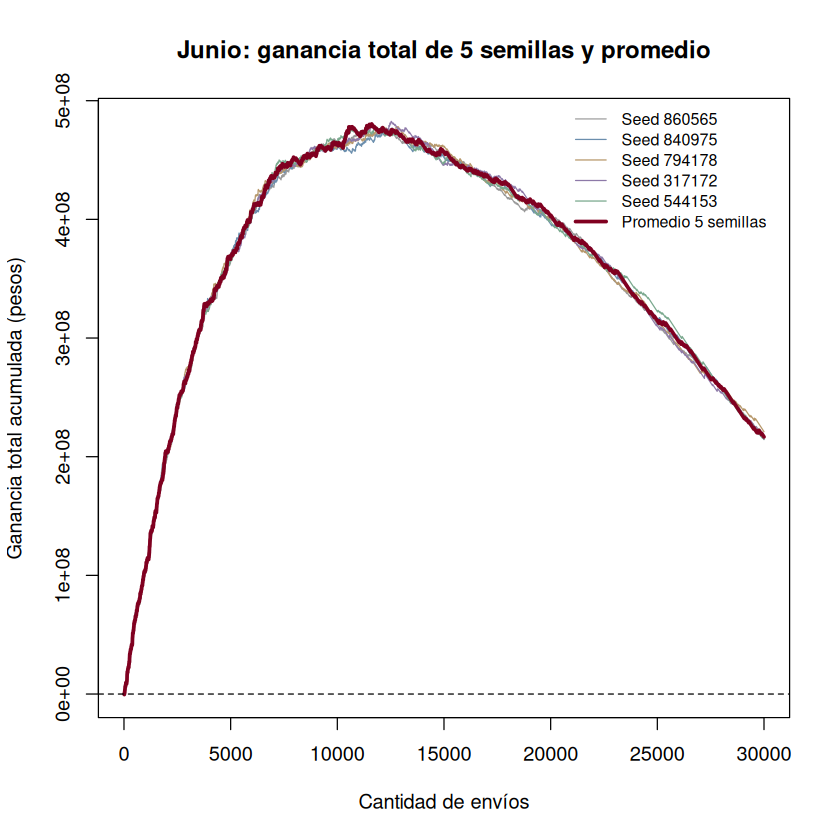

In [36]:
# ============================================================
# Evaluación de junio con 5 semillas
# Entrenamiento: marzo-abril | Predicción: junio
# Aplica las variables seleccionadas con canaritos
# ============================================================

local({

  library(data.table)
  library(lightgbm)

  MESES_TRAIN <- c(202103L, 202104L)
  MES_EVALUACION <- 202106L

  stopifnot(
    length(PARAM$semillas) >= 5L,
    !anyNA(PARAM$semillas),
    !anyDuplicated(PARAM$semillas)
  )

  semillas_junio <- as.integer(PARAM$semillas[1:5])

  CORTES_JUNIO <- seq(8000L, 15000L, by = 500L)
  EXCLUIR_JUNIO <- character()
  # EXCLUIR_JUNIO <- c("rank_variable1", "rank_variable2")

  GANANCIA_BAJA2 <- 1072500
  COSTO_OTROS <- -27500
  HILOS_JUNIO <- 4L

  if (is.null(PARAM$usar_canaritos)) {
    stop("Definí PARAM$usar_canaritos <- TRUE o FALSE.")
  }

  ETIQUETA <- if (isTRUE(PARAM$usar_canaritos)) {
    "evaluacion_junio_5_semillas_canaritos_filtro30"
  } else {
    "evaluacion_junio_5_semillas_filtro30"
  }

  carpeta <- file.path(
    "/home/ds/buckets/b1/exp",
    PARAM$experimento,
    ETIQUETA
  )

  dir.create(carpeta, recursive = TRUE, showWarnings = FALSE)

  for (subcarpeta in c("modelos", "probabilidades", "campania")) {
    dir.create(
      file.path(carpeta, subcarpeta),
      showWarnings = FALSE
    )
  }

  guardar_csv <- function(tabla, archivo) {
    temporal <- paste0(archivo, ".tmp")
    fwrite(tabla, temporal, quote = FALSE)

    if (!file.rename(temporal, archivo)) {
      stop("No se pudo guardar: ", archivo)
    }
  }

  # ==========================================================
  # 1. Liberar datos anteriores y leer el dataset
  # ==========================================================

  rm(
    list = intersect(
      c(
        "dataset", "dataset_train", "dataset_valid",
        "dtrain", "dvalidate", "modelo"
      ),
      ls(envir = .GlobalEnv)
    ),
    envir = .GlobalEnv
  )
  gc()

  datos <- fread(
    "/home/ds/buckets/b1/datasets/competencia_01_ct10.csv.gz",
    stringsAsFactors = TRUE
  )

  campos_junio <- setdiff(
    names(datos),
    c(
      "numero_de_cliente","clase_ternaria", "clase01", "fold", "azar",
      "training", "training30", "prob30", "aporta",
      EXCLUIR_JUNIO
    )
  )

  # ==========================================================
  # 2. Aplicar la selección de canaritos
  # ==========================================================

  if (isTRUE(PARAM$usar_canaritos)) {

    archivo_seleccion <- file.path(
      "/home/ds/buckets/b1/exp",
      PARAM$experimento,
      "canaritos",
      "seleccion.rds"
    )

    if (!file.exists(archivo_seleccion)) {
      stop("Primero ejecutá la selección de canaritos.")
    }

    if (!setequal(PARAM$train, MESES_TRAIN)) {
      stop(
        "Para evaluar junio, ejecutá los canaritos con ",
        "PARAM$train <- c(202103, 202104)."
      )
    }

    seleccion_junio <- readRDS(archivo_seleccion)

    stopifnot(
      is.character(seleccion_junio$campos),
      length(seleccion_junio$campos) > 0L,
      !anyNA(seleccion_junio$campos),
      !anyDuplicated(seleccion_junio$campos),
      all(seleccion_junio$campos %in% campos_junio |
            seleccion_junio$campos %in% EXCLUIR_JUNIO)
    )

    campos_junio <- seleccion_junio$campos[
      !seleccion_junio$campos %in% EXCLUIR_JUNIO
    ]

    rm(seleccion_junio)
  }

  stopifnot(length(campos_junio) > 0L)

  cat("\nPredictores para junio:", length(campos_junio), "\n")

  columnas_necesarias <- unique(c(
    "numero_de_cliente", "foto_mes", "clase_ternaria",
    campos_junio
  ))

  tr <- datos[
    foto_mes %in% MESES_TRAIN,
    columnas_necesarias,
    with = FALSE
  ]

  fu <- datos[
    foto_mes == MES_EVALUACION,
    columnas_necesarias,
    with = FALSE
  ]

  rm(datos)
  gc()

  stopifnot(
    all(MESES_TRAIN %in% tr$foto_mes),
    nrow(fu) >= max(CORTES_JUNIO),
    !anyNA(tr$clase_ternaria),
    !anyNA(fu$clase_ternaria),
    all(tr$clase_ternaria %in%
          c("CONTINUA", "BAJA+1", "BAJA+2")),
    all(fu$clase_ternaria %in%
          c("CONTINUA", "BAJA+1", "BAJA+2")),
    !anyNA(fu$numero_de_cliente),
    !anyDuplicated(fu$numero_de_cliente)
  )

  ids_numericos <- as.numeric(
    as.character(fu$numero_de_cliente)
  )

  stopifnot(
    all(is.finite(ids_numericos)),
    all(ids_numericos == trunc(ids_numericos)),
    all(abs(ids_numericos) < 2^53)
  )

  ids <- sprintf("%.0f", ids_numericos)

  stopifnot(
    !anyDuplicated(ids),
    all(grepl("^[0-9]+$", ids))
  )

  referencia <- data.table(
    numero_de_cliente = ids,
    foto_mes = MES_EVALUACION,
    clase_ternaria = as.character(fu$clase_ternaria)
  )

  parametros <- param_final
  parametros$num_threads <- HILOS_JUNIO

  # ==========================================================
  # 3. Verificar configuración y guardar la lista de semillas
  # ==========================================================

  configuracion <- list(
    train = MESES_TRAIN,
    future = MES_EVALUACION,
    semillas = semillas_junio,
    campos = campos_junio,
    parametros = parametros,
    target = c("BAJA+1", "BAJA+2"),
    usar_canaritos = isTRUE(PARAM$usar_canaritos),
    filtro = list(
      version = "modelo30_crossfit_v1",
      undersampling30 = PARAM$ruido$undersampling30,
      umbral = PARAM$ruido$umbral,
      semilla = PARAM$semilla_primigenia
    )
  )

  archivo_config <- file.path(carpeta, "configuracion.rds")

  if (file.exists(archivo_config)) {

    if (!identical(readRDS(archivo_config), configuracion)) {
      stop(
        "Cambió la configuración. Cambiá ETIQUETA ",
        "para guardar los nuevos resultados en otra carpeta."
      )
    }

  } else {

    temporal <- paste0(archivo_config, ".tmp")
    saveRDS(configuracion, temporal)

    if (!file.rename(temporal, archivo_config)) {
      stop("No se pudo guardar la configuración.")
    }
  }

  # Lista de las 5 semillas previstas para esta evaluación
  guardar_csv(
    data.table(
      modelo = seq_along(semillas_junio),
      seed = semillas_junio
    ),
    file.path(carpeta, "semillas_modelos.csv")
  )

  # ==========================================================
  # 4. Filtrar registros y preparar LightGBM
  # ==========================================================

  tr <- filtrar_con_checkpoint(
    dt = tr,
    campos = campos_junio,
    semilla = PARAM$semilla_primigenia,
    archivo = file.path(carpeta, "filtro_junio.rds"),
    undersampling30 = PARAM$ruido$undersampling30,
    umbral = PARAM$ruido$umbral
  )

  gc()

  dtrain_junio <- lgb.Dataset(
    data = data.matrix(tr[, campos_junio, with = FALSE]),
    label = as.integer(
      tr$clase_ternaria %in% c("BAJA+1", "BAJA+2")
    ),
    params = parametros,
    free_raw_data = TRUE
  )

  dtrain_junio$construct()

  rm(tr)
  gc()

  X_junio <- data.matrix(fu[, campos_junio, with = FALSE])

  rm(fu, ids_numericos)
  gc()

  # ==========================================================
  # 5. Función para calcular ganancias y generar campañas
  # ==========================================================

  evaluar <- function(prob, etiqueta) {

    stopifnot(
      length(prob) == nrow(referencia),
      all(is.finite(prob)),
      all(prob >= 0 & prob <= 1)
    )

    tabla <- copy(referencia)
    set(tabla, j = "prob", value = prob)

    tabla[, id_orden := as.numeric(numero_de_cliente)]
    setorder(tabla, -prob, id_orden)
    tabla[, id_orden := NULL]

    tabla[, gan := fifelse(
      clase_ternaria == "BAJA+2",
      GANANCIA_BAJA2,
      COSTO_OTROS
    )]

    tabla[, ganancia_acumulada := cumsum(gan)]
    tabla[, baja2_acumuladas := cumsum(
      clase_ternaria == "BAJA+2"
    )]
    tabla[, envios := seq_len(.N)]

    guardar_csv(
      tabla,
      file.path(
        carpeta,
        "probabilidades",
        paste0("predicciones_junio_", etiqueta, ".csv")
      )
    )

    resumen <- tabla[
      envios %in% CORTES_JUNIO,
      .(
        modelo = etiqueta,
        envios,
        baja2 = baja2_acumuladas,
        ganancia_total = ganancia_acumulada
      )
    ]

    for (corte in CORTES_JUNIO) {
      writeLines(
        tabla$numero_de_cliente[seq_len(corte)],
        file.path(
          carpeta,
          "campania",
          paste0("junio_", etiqueta, "_top_", corte, ".csv")
        ),
        useBytes = TRUE
      )
    }

    list(
      resumen = resumen,
      curva = tabla[
        envios <= min(30000L, nrow(tabla)),
        .(envios, ganancia_acumulada)
      ]
    )
  }

  # ==========================================================
  # 6. Entrenar o recuperar las 5 semillas
  # ==========================================================

  suma_prob <- numeric(nrow(referencia))
  resultados <- vector("list", length(semillas_junio))
  curvas <- vector("list", length(semillas_junio))

  for (i in seq_along(semillas_junio)) {

    semilla <- semillas_junio[i]
    etiqueta <- paste0("seed_", semilla)

    cat(
      "\nModelo", i, "de", length(semillas_junio),
      "| seed:", semilla, "\n"
    )
    flush.console()

    archivo_modelo <- file.path(
      carpeta,
      "modelos",
      paste0("modelo_", semilla, ".txt")
    )

    archivo_prob <- file.path(
      carpeta,
      "probabilidades",
      paste0("predicciones_junio_", etiqueta, ".csv")
    )

    if (file.exists(archivo_prob)) {

      cat("Recuperando probabilidades guardadas...\n")

      anterior <- fread(
        archivo_prob,
        colClasses = c(numero_de_cliente = "character")
      )

      stopifnot(
        all(c(
          "numero_de_cliente", "foto_mes",
          "clase_ternaria", "prob"
        ) %in% names(anterior)),
        !anyNA(anterior$numero_de_cliente),
        !anyDuplicated(anterior$numero_de_cliente),
        nrow(anterior) == nrow(referencia),
        setequal(
          anterior$numero_de_cliente,
          referencia$numero_de_cliente
        ),
        !anyNA(anterior$foto_mes),
        all(anterior$foto_mes == MES_EVALUACION),
        is.numeric(anterior$prob),
        all(is.finite(anterior$prob)),
        all(anterior$prob >= 0 & anterior$prob <= 1)
      )

      orden <- match(
        referencia$numero_de_cliente,
        anterior$numero_de_cliente
      )

      stopifnot(
        identical(
          as.character(anterior$clase_ternaria[orden]),
          referencia$clase_ternaria
        )
      )

      prob <- anterior$prob[orden]
      rm(anterior, orden)

    } else {

      if (file.exists(archivo_modelo)) {

        cat("Recuperando modelo guardado...\n")
        modelo <- lgb.load(archivo_modelo)

      } else {

        p <- parametros
        p$seed <- semilla

        tiempo <- system.time({
          modelo <- lgb.train(
            data = dtrain_junio,
            params = p
          )
        })

        cat(
          "Entrenamiento:",
          tiempo[["elapsed"]], "segundos\n"
        )

        temporal <- paste0(archivo_modelo, ".tmp")
        lgb.save(modelo, temporal)

        if (!file.rename(temporal, archivo_modelo)) {
          stop("No se pudo guardar el modelo.")
        }
      }

      prob <- predict(
        modelo,
        X_junio,
        params = list(num_threads = HILOS_JUNIO)
      )

      rm(modelo)
      invisible(gc())
    }

    evaluacion <- evaluar(prob, etiqueta)

    suma_prob <- suma_prob + prob
    resultados[[i]] <- evaluacion$resumen
    curvas[[i]] <- evaluacion$curva

    rm(prob, evaluacion)
  }

  rm(dtrain_junio, X_junio)
  gc()

  # ==========================================================
  # 7. Promedio de las 5 semillas y tabla de ganancias
  # ==========================================================

  evaluacion_promedio <- evaluar(
    suma_prob / length(semillas_junio),
    "promedio_5_semillas"
  )

  resumen_total <- rbindlist(c(
    resultados,
    list(evaluacion_promedio$resumen)
  ))

  guardar_csv(
    resumen_total,
    file.path(carpeta, "ganancia_por_corte.csv")
  )

  tabla_ganancias <- resumen_total[
    modelo == "promedio_5_semillas",
    .(
      Envios = envios,
      BAJA2_detectadas = baja2,
      Ganancia_total = ganancia_total
    )
  ]

  guardar_csv(
    tabla_ganancias,
    file.path(carpeta, "ganancia_promedio_5_semillas.csv")
  )

  cat(
    "\nGANANCIA TOTAL DEL PROMEDIO DE LAS 5 SEMILLAS\n",
    "Cortes entre 8.000 y 15.000 envíos\n\n"
  )

  print(tabla_ganancias, nrows = nrow(tabla_ganancias))

  # ==========================================================
  # 8. Curva de ganancia total acumulada
  # ==========================================================

  dibujar_curva <- function() {

    colores <- c(
      "#999999", "#6B8EAD", "#B7986B",
      "#8D79A8", "#79A88D"
    )

    valores <- c(
      0,
      unlist(lapply(
        curvas,
        function(x) x$ganancia_acumulada
      )),
      evaluacion_promedio$curva$ganancia_acumulada
    )

    plot(
      evaluacion_promedio$curva$envios,
      evaluacion_promedio$curva$ganancia_acumulada,
      type = "n",
      ylim = range(valores, finite = TRUE),
      xlab = "Cantidad de envíos",
      ylab = "Ganancia total acumulada (pesos)",
      main = "Junio: ganancia total de 5 semillas y promedio"
    )

    for (i in seq_along(curvas)) {
      lines(
        curvas[[i]]$envios,
        curvas[[i]]$ganancia_acumulada,
        col = colores[i],
        lwd = 1
      )
    }

    lines(
      evaluacion_promedio$curva$envios,
      evaluacion_promedio$curva$ganancia_acumulada,
      col = "#800020",
      lwd = 3
    )

    abline(h = 0, lty = 2)

    legend(
      "topright",
      legend = c(
        paste0("Seed ", semillas_junio),
        "Promedio 5 semillas"
      ),
      col = c(colores, "#800020"),
      lwd = c(rep(1, length(semillas_junio)), 3),
      cex = 0.8,
      bty = "n"
    )
  }

  dibujar_curva()

  png(
    file.path(carpeta, "curva_ganancia_total_junio.png"),
    width = 1600,
    height = 900,
    res = 150
  )

  tryCatch(
    dibujar_curva(),
    finally = dev.off()
  )

  cat("\nResultados guardados en:", carpeta, "\n")
})

gc()

In [37]:
# ============================================================
# 3. Preparar marzo–junio y agosto
# Reincorporar las 42 variables de préstamos para agosto
# ============================================================

library(data.table)

setwd(carpeta_experimento)

# Liberar datos anteriores y objetos de entrenamiento de la BO
rm(list = intersect(
  c(
    "dataset", "dataset_train", "dataset_valid",
    "dfuture", "dtrain", "dvalidate", "modelo"
  ),
  ls()
))
gc()

# Volver a leer el dataset
dataset <- fread(
  "/home/ds/buckets/b1/datasets/competencia_01_ct10.csv.gz",
  stringsAsFactors = TRUE
)

# Exclusiones adicionales para agosto
EXCLUIR_AGOSTO <- character()
# EXCLUIR_AGOSTO <- c("rank_variable1", "rank_variable2")

# Predictores candidatos
campos_buenos <- setdiff(
  names(dataset),
  c(
    "numero_de_cliente","clase_ternaria", "clase01", "fold", "azar",
    "training", "training30", "prob30", "aporta",
    EXCLUIR_AGOSTO
  )
)

# ============================================================
# Recuperar y aplicar la selección de canaritos
# ============================================================

if (is.null(PARAM$usar_canaritos)) {
  stop(
    "Definí PARAM$usar_canaritos <- TRUE o FALSE ",
    "antes de ejecutar esta celda."
  )
}

if (isTRUE(PARAM$usar_canaritos)) {

  archivo_seleccion <- file.path(
    "/home/ds/buckets/b1/exp",
    PARAM$experimento,
    "canaritos",
    "seleccion.rds"
  )

  if (!file.exists(archivo_seleccion)) {
    stop(
      "No se encontró la selección de canaritos. ",
      "Ejecutá primero la celda de selección."
    )
  }

  seleccion_agosto <- readRDS(archivo_seleccion)

  stopifnot(
    is.character(seleccion_agosto$campos),
    length(seleccion_agosto$campos) > 0L,
    !anyNA(seleccion_agosto$campos),
    !anyDuplicated(seleccion_agosto$campos),
    all(seleccion_agosto$campos %in% campos_buenos |
          seleccion_agosto$campos %in% EXCLUIR_AGOSTO)
  )

  # Mantener el orden de las variables seleccionadas
  campos_buenos <- seleccion_agosto$campos[
    !seleccion_agosto$campos %in% EXCLUIR_AGOSTO
  ]

  cat(
    "\nCanaritos activados.",
    "\nPredictores recuperados de la selección:",
    length(campos_buenos), "\n"
  )

  rm(seleccion_agosto)

} else {

  cat(
    "\nCanaritos desactivados.",
    "\nPredictores candidatos:",
    length(campos_buenos), "\n"
  )
}

# ============================================================
# Reincorporar las 42 variables de préstamos para agosto
# No modificar la selección guardada para la BO
# ============================================================

bases_prestamos <- c(
  "cprestamos_personales",
  "mprestamos_personales"
)

campos_prestamos <- unlist(
  lapply(bases_prestamos, function(variable) {
    c(
      variable,
      paste0("Lag1_", variable),
      paste0("Lag2_", variable),
      paste0("Delta1_", variable),
      paste0("Delta2_", variable),
      paste0(variable, "_tend3"),
      paste0(variable, "_avg3")
    )
  }),
  use.names = FALSE
)

variables_prestamos <- unlist(
  lapply(
    c("rank_", "las_zero_", "missing_"),
    function(prefijo) paste0(prefijo, campos_prestamos)
  ),
  use.names = FALSE
)

# Verificar que existan todas
faltantes <- setdiff(variables_prestamos, names(dataset))

if (length(faltantes)) {
  stop(
    "Faltan variables de préstamos: ",
    paste(faltantes, collapse = ", ")
  )
}

# Evitar instrucciones contradictorias
conflictos <- intersect(variables_prestamos, EXCLUIR_AGOSTO)

if (length(conflictos)) {
  stop(
    "Estas variables de préstamos también están en EXCLUIR_AGOSTO: ",
    paste(conflictos, collapse = ", ")
  )
}

cantidad_antes <- length(campos_buenos)

# Agregar las 42 variables sin duplicar las que ya estaban
campos_buenos <- unique(c(
  campos_buenos,
  variables_prestamos
))

stopifnot(
  length(variables_prestamos) == 42L,
  all(variables_prestamos %in% campos_buenos),
  length(campos_buenos) > 0L,
  all(campos_buenos %in% names(dataset))
)

cat(
  "\nVariables de préstamos incluidas:",
  length(variables_prestamos),
  "\nVariables adicionales incorporadas:",
  length(campos_buenos) - cantidad_antes,
  "\nTotal de predictores para agosto:",
  length(campos_buenos), "\n"
)

# ============================================================
# Separar entrenamiento y predicción
# ============================================================

columnas_necesarias <- unique(c(
  "numero_de_cliente",
  "foto_mes",
  "clase_ternaria",
  campos_buenos
))

dataset_train <- dataset[
  foto_mes %in% PARAM$train_final,
  columnas_necesarias,
  with = FALSE
]

dfuture <- dataset[
  foto_mes %in% PARAM$future,
  columnas_necesarias,
  with = FALSE
]

# Liberar el dataset completo
rm(dataset)
gc()

stopifnot(
  all(PARAM$train_final %in% dataset_train$foto_mes),
  all(PARAM$future %in% dfuture$foto_mes),
  nrow(dfuture) > 0L,
  !anyNA(dataset_train$clase_ternaria),
  all(dataset_train$clase_ternaria %in%
        c("CONTINUA", "BAJA+1", "BAJA+2")),
  all(campos_buenos %in% names(dataset_train)),
  all(campos_buenos %in% names(dfuture)),
  !anyNA(dfuture$numero_de_cliente),
  !anyDuplicated(dfuture$numero_de_cliente)
)

dataset_train[, clase01 :=
  as.integer(clase_ternaria %in% c("BAJA+1", "BAJA+2"))]

print(
  dataset_train[, .N, by = .(foto_mes, clase_ternaria)]
)

# ============================================================
# Preparar IDs de agosto
# ============================================================

ids_numericos <- as.numeric(
  as.character(dfuture$numero_de_cliente)
)

stopifnot(
  all(is.finite(ids_numericos)),
  all(ids_numericos == trunc(ids_numericos)),
  all(abs(ids_numericos) < 2^53)
)

ids_agosto <- sprintf("%.0f", ids_numericos)

stopifnot(
  !anyDuplicated(ids_agosto),
  all(grepl("^[0-9]+$", ids_agosto))
)

cat(
  "\nRegistros de entrenamiento:", nrow(dataset_train),
  "\nClientes de agosto:", length(ids_agosto),
  "\nPredictores utilizados:", length(campos_buenos),
  "\n"
)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2710889,144.8,4785227,255.6,4785227,255.6
Vcells,4571143,34.9,109705344,837.0,5633483878,42980.1



Canaritos activados. 
Predictores recuperados de la selección: 353 

Variables de préstamos incluidas: 42 
Variables adicionales incorporadas: 42 
Total de predictores para agosto: 395 


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2712046,144.9,4785227,255.6,4785227,255.6
Vcells,262063541,1999.4,3708566788,28294.2,5633483878,42980.1


    foto_mes clase_ternaria      N
       <int>         <fctr>  <int>
 1:   202103       CONTINUA 160921
 2:   202103         BAJA+2    960
 3:   202103         BAJA+1   1019
 4:   202104       CONTINUA 161181
 5:   202104         BAJA+2   1139
 6:   202104         BAJA+1    964
 7:   202105       CONTINUA 161755
 8:   202105         BAJA+1   1143
 9:   202105         BAJA+2    870
10:   202106       CONTINUA 162142
11:   202106         BAJA+2   1098
12:   202106         BAJA+1    874

Registros de entrenamiento: 654066 
Clientes de agosto: 164647 
Predictores utilizados: 395 


In [38]:
# ============================================================
# 4. Preparar LightGBM con checkpoint del filtrado
# ============================================================

objetos_liberar <- intersect(
  c("dtrain", "dvalidate", "dataset_valid"),
  ls()
)

rm(list = objetos_liberar)
gc()

# Checkpoint del filtrado marzo-junio
archivo_filtro_agosto <- file.path(
  carpeta_experimento,
  "filtro_agosto.rds"
)

dataset_train <- filtrar_con_checkpoint(
  dt = dataset_train,
  campos = campos_buenos,
  semilla = PARAM$semilla_primigenia,
  archivo = archivo_filtro_agosto,
  undersampling30 = PARAM$ruido$undersampling30,
  umbral = PARAM$ruido$umbral
)

param_final$num_threads <- 4L

dtrain_final <- lgb.Dataset(
  data = data.matrix(
    dataset_train[, campos_buenos, with = FALSE]
  ),
  label = dataset_train$clase01,
  params = param_final,
  free_raw_data = TRUE
)

dtrain_final$construct()

rm(dataset_train)
gc()

# Agosto: predecir todos los clientes
X_agosto <- data.matrix(
  dfuture[, campos_buenos, with = FALSE]
)

rm(dfuture, ids_numericos)
gc()

suma_prob <- numeric(length(ids_agosto))

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2875627,153.6,4785227,255.6,4785227,255.6
Vcells,263046568,2006.9,2966853431,22635.3,5633483878,42980.1



No existe checkpoint. Ejecutando modelo30...
   foto_mes  total eliminados conservados porcentaje_conservado
      <int>  <int>      <int>       <int>                 <num>
1:   202103 162900       3941      158959                 97.58
2:   202104 163284       4002      159282                 97.55
3:   202105 163768       3979      159789                 97.57
4:   202106 164114       4198      159916                 97.44
Checkpoint guardado: /home/ds/buckets/b1/exp/Experimento 32/agosto_v01/filtro_agosto.rds 

Resumen del filtrado:
   foto_mes  total conservados eliminados
      <int>  <int>       <int>      <int>
1:   202103 162900      158959       3941
2:   202104 163284      159282       4002
3:   202105 163768      159789       3979
4:   202106 164114      159916       4198


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2875390,153.6,4785227,255.6,4785227,255.6
Vcells,57651521,439.9,1519028957,11589.3,5633483878,42980.1


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2874953,153.6,4785227,255.6,4785227,255.6
Vcells,70739377,539.7,1215223166,9271.5,5633483878,42980.1


In [39]:
# ============================================================
# 5. Entrenar o recuperar las semillas seleccionadas de agosto
# ============================================================

library(data.table)
library(lightgbm)

setwd(carpeta_experimento)

param_final$num_threads <- 4L

stopifnot(
  length(semillas_agosto) > 0L,
  !anyNA(semillas_agosto),
  !anyDuplicated(semillas_agosto),
  length(ids_agosto) > 0L,
  !anyNA(ids_agosto),
  !anyDuplicated(ids_agosto),
  nrow(X_agosto) == length(ids_agosto)
)

for (carpeta in c(
  "modelos", "probabilidades", "feature_importance"
)) {
  dir.create(carpeta, showWarnings = FALSE)
}

# Guardado mediante archivo temporal
guardar_csv <- function(tabla, archivo) {

  temporal <- paste0(archivo, ".tmp")
  fwrite(tabla, temporal, quote = FALSE)

  if (!file.rename(temporal, archivo)) {
    stop("No se pudo guardar: ", archivo)
  }
}

# Reconstruir el registro de esta ejecución
semillas_completadas <- integer()

for (i in seq_along(semillas_agosto)) {

  semilla <- semillas_agosto[i]

  cat(
    "\nModelo", i, "de", length(semillas_agosto),
    "| seed:", semilla, "\n"
  )
  flush.console()

  archivo_modelo <- file.path(
    "modelos",
    paste0("modelo_", semilla, ".txt")
  )

  archivo_prob <- file.path(
    "probabilidades",
    paste0("probabilidades_202108_seed_", semilla, ".csv")
  )

  modelo <- NULL
  tabla_prob <- NULL

  # ==========================================================
  # Recuperar probabilidades completas, si ya existen
  # ==========================================================

  if (file.exists(archivo_prob)) {

    cat("Recuperando probabilidades guardadas...\n")
    flush.console()

    tabla_prob <- fread(
      archivo_prob,
      colClasses = c(numero_de_cliente = "character")
    )

    stopifnot(
      all(c(
        "numero_de_cliente", "foto_mes", "prob"
      ) %in% names(tabla_prob)),
      nrow(tabla_prob) == length(ids_agosto),
      !anyNA(tabla_prob$numero_de_cliente),
      !anyDuplicated(tabla_prob$numero_de_cliente),
      setequal(tabla_prob$numero_de_cliente, ids_agosto),
      !anyNA(tabla_prob$foto_mes),
      all(tabla_prob$foto_mes == 202108L),
      is.numeric(tabla_prob$prob),
      all(is.finite(tabla_prob$prob)),
      all(tabla_prob$prob >= 0 & tabla_prob$prob <= 1)
    )

  } else {

    # ========================================================
    # Recuperar o entrenar el modelo
    # ========================================================

    if (file.exists(archivo_modelo)) {

      cat("Recuperando modelo guardado...\n")
      flush.console()

      modelo <- lgb.load(archivo_modelo)

    } else {

      parametros_modelo <- param_final
      parametros_modelo$seed <- semilla

      cat("Entrenando con 8 hilos...\n")
      flush.console()

      tiempo <- system.time({
        modelo <- lgb.train(
          data = dtrain_final,
          params = parametros_modelo
        )
      })

      cat(
        "Entrenamiento:",
        tiempo[["elapsed"]], "segundos\n"
      )

      temporal <- paste0(archivo_modelo, ".tmp")
      lgb.save(modelo, temporal)

      if (!file.rename(temporal, archivo_modelo)) {
        stop("No se pudo guardar el modelo: ", archivo_modelo)
      }
    }

    # ========================================================
    # Predecir agosto y guardar las probabilidades completas
    # ========================================================

    cat("Prediciendo agosto...\n")
    flush.console()

    tiempo <- system.time({
      prob <- predict(
        modelo,
        X_agosto,
        params = list(num_threads = 4L)
      )
    })

    cat(
      "Predicción:",
      tiempo[["elapsed"]], "segundos\n"
    )

    stopifnot(
      length(prob) == length(ids_agosto),
      all(is.finite(prob)),
      all(prob >= 0 & prob <= 1)
    )

    tabla_prob <- data.table(
      numero_de_cliente = ids_agosto,
      foto_mes = 202108L,
      prob = prob
    )

    setorder(tabla_prob, -prob, numero_de_cliente)

    guardar_csv(tabla_prob, archivo_prob)

    rm(prob)
  }

  # Registrar solo después de validar o guardar la predicción
  semillas_completadas <- c(
    semillas_completadas,
    semilla
  )

  guardar_csv(
    data.table(seed = semillas_completadas),
    "semillas_completadas.csv"
  )

  cat(
    "Semilla completada:", semilla,
    "| Completadas:", length(semillas_completadas), "\n"
  )
  flush.console()

  rm(modelo, tabla_prob)
  invisible(gc())
}

cat(
  "\nProceso terminado:",
  length(semillas_completadas),
  "semillas completas.\n"
)


Modelo 1 de 50 | seed: 860565 
Entrenando con 8 hilos...
Entrenamiento: 754.021 segundos
Prediciendo agosto...
Predicción: 68.426 segundos
Semilla completada: 860565 | Completadas: 1 

Modelo 2 de 50 | seed: 840975 
Entrenando con 8 hilos...
Entrenamiento: 728.132 segundos
Prediciendo agosto...
Predicción: 93.27 segundos
Semilla completada: 840975 | Completadas: 2 

Modelo 3 de 50 | seed: 794178 
Entrenando con 8 hilos...
Entrenamiento: 721.566 segundos
Prediciendo agosto...
Predicción: 64.949 segundos
Semilla completada: 794178 | Completadas: 3 

Modelo 4 de 50 | seed: 317172 
Entrenando con 8 hilos...
Entrenamiento: 730.233 segundos
Prediciendo agosto...
Predicción: 64.144 segundos
Semilla completada: 317172 | Completadas: 4 

Modelo 5 de 50 | seed: 544153 
Entrenando con 8 hilos...
Entrenamiento: 732.366 segundos
Prediciendo agosto...
Predicción: 78.739 segundos
Semilla completada: 544153 | Completadas: 5 

Modelo 6 de 50 | seed: 712496 
Entrenando con 8 hilos...
Entrenamiento: 727

Timing stopped at: 1118 2.631 287.3



In [40]:
# ============================================================
# 6. Promediar las predicciones completas de agosto
# Puede ejecutarse aunque el entrenamiento se haya interrumpido
# ============================================================

library(data.table)

carpeta_experimento <- file.path(
  "/home/ds/buckets/b1/exp",
  PARAM$experimento,
  PARAM$version_agosto
)

# ============================================================
# Recuperar la lista COMPLETA de semillas disponibles
# ============================================================

archivo_semillas <- file.path(
  carpeta_experimento,
  "semillas_modelos.csv"
)

if (!file.exists(archivo_semillas)) {
  stop("Primero ejecutá la celda de configuración de agosto.")
}

semillas_guardadas <- as.integer(
  fread(archivo_semillas)$seed
)

stopifnot(
  length(semillas_guardadas) > 0L,
  !anyNA(semillas_guardadas),
  !anyDuplicated(semillas_guardadas),
  length(N_SEMILLAS_AGOSTO) == 1L,
  !is.na(N_SEMILLAS_AGOSTO),
  N_SEMILLAS_AGOSTO >= 1L,
  N_SEMILLAS_AGOSTO == as.integer(N_SEMILLAS_AGOSTO),
  N_SEMILLAS_AGOSTO <= length(semillas_guardadas)
)

semillas_agosto <- head(
  semillas_guardadas,
  N_SEMILLAS_AGOSTO
)

# ============================================================
# Recuperar los IDs originales de agosto
# ============================================================

if (exists("ids_agosto", inherits = FALSE)) {

  ids <- as.character(ids_agosto)

} else {

  # Después de reiniciar: leer únicamente ID y mes
  referencia <- fread(
    "/home/ds/buckets/b1/datasets/competencia_01_ct10.csv.gz",
    select = c("numero_de_cliente", "foto_mes"),
    colClasses = c(numero_de_cliente = "character")
  )

  ids <- referencia[
    foto_mes == 202108L,
    numero_de_cliente
  ]

  rm(referencia)
  gc()
}

stopifnot(
  length(ids) > 0L,
  !anyNA(ids),
  !anyDuplicated(ids),
  all(grepl("^[0-9]+$", ids))
)

# ============================================================
# Leer y validar las predicciones individuales
# ============================================================

# Reconstruir desde cero en cada ejecución
suma_prob <- numeric(length(ids))
semillas_completadas <- integer()

for (semilla in semillas_agosto) {

  archivo <- file.path(
    carpeta_experimento,
    "probabilidades",
    paste0(
      "probabilidades_202108_seed_",
      semilla,
      ".csv"
    )
  )

  if (!file.exists(archivo)) {
    cat("Sin predicción guardada:", semilla, "\n")
    next
  }

  tabla <- tryCatch(
    fread(
      archivo,
      colClasses = c(numero_de_cliente = "character")
    ),
    error = function(e) {
      cat(
        "No se pudo leer la semilla", semilla,
        ":", conditionMessage(e), "\n"
      )
      NULL
    }
  )

  completa <- !is.null(tabla) &&
    all(c(
      "numero_de_cliente", "foto_mes", "prob"
    ) %in% names(tabla)) &&
    nrow(tabla) == length(ids) &&
    !anyNA(tabla$numero_de_cliente) &&
    !anyDuplicated(tabla$numero_de_cliente) &&
    setequal(tabla$numero_de_cliente, ids) &&
    !anyNA(tabla$foto_mes) &&
    all(tabla$foto_mes == 202108L) &&
    is.numeric(tabla$prob) &&
    all(is.finite(tabla$prob)) &&
    all(tabla$prob >= 0 & tabla$prob <= 1)

  if (!completa) {

    cat(
      "Predicción incompleta o inválida; se omite:",
      semilla, "\n"
    )

    rm(tabla)
    next
  }

  # Alinear por cliente antes de sumar
  suma_prob <- suma_prob +
    tabla$prob[match(ids, tabla$numero_de_cliente)]

  semillas_completadas <- c(
    semillas_completadas,
    semilla
  )

  cat("Incluida en el promedio:", semilla, "\n")
  flush.console()

  rm(tabla)
}

cantidad_completadas <- length(semillas_completadas)

if (cantidad_completadas == 0L) {
  stop("No hay predicciones completas para promediar.")
}

# ============================================================
# Calcular el promedio con las semillas realmente completadas
# ============================================================

tabla_promedio <- data.table(
  numero_de_cliente = ids,
  foto_mes = 202108L,
  prob = suma_prob / cantidad_completadas
)

setorder(tabla_promedio, -prob, numero_de_cliente)

guardar_csv_promedio <- function(tabla, archivo) {

  temporal <- paste0(archivo, ".tmp")
  fwrite(tabla, temporal, quote = FALSE)

  if (!file.rename(temporal, archivo)) {
    stop("No se pudo guardar: ", archivo)
  }
}

# Actualizar el promedio que utilizará la celda de campañas
guardar_csv_promedio(
  tabla_promedio,
  file.path(
    carpeta_experimento,
    "probabilidades",
    "probabilidades_202108_promedio_semillas.csv"
  )
)

# Guardar únicamente las semillas incluidas en este promedio
# No modificar semillas_modelos.csv
guardar_csv_promedio(
  data.table(seed = semillas_completadas),
  file.path(
    carpeta_experimento,
    "semillas_completadas.csv"
  )
)

cat(
  "\nPromedio actualizado con",
  cantidad_completadas,
  "semillas completas de",
  N_SEMILLAS_AGOSTO,
  "seleccionadas.\n"
)

print(semillas_completadas)

# Liberar objetos grandes si siguen en memoria
rm(list = intersect(
  c("dtrain_final", "X_agosto"),
  ls()
))

gc()

Incluida en el promedio: 860565 
Incluida en el promedio: 840975 
Incluida en el promedio: 794178 
Incluida en el promedio: 317172 
Incluida en el promedio: 544153 
Incluida en el promedio: 712496 
Incluida en el promedio: 362241 
Incluida en el promedio: 218251 
Incluida en el promedio: 880204 
Incluida en el promedio: 595509 
Incluida en el promedio: 410278 
Incluida en el promedio: 437908 
Incluida en el promedio: 352479 
Incluida en el promedio: 970743 
Incluida en el promedio: 845897 
Sin predicción guardada: 317007 
Sin predicción guardada: 526917 
Sin predicción guardada: 298267 
Sin predicción guardada: 450178 
Sin predicción guardada: 540438 
Sin predicción guardada: 876685 
Sin predicción guardada: 666137 
Sin predicción guardada: 275241 
Sin predicción guardada: 585243 
Sin predicción guardada: 922319 
Sin predicción guardada: 574411 
Sin predicción guardada: 239079 
Sin predicción guardada: 831707 
Sin predicción guardada: 249643 
Sin predicción guardada: 321908 
Sin predic

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2876798,153.7,4785227,255.6,4785227,255.6
Vcells,6285251,48.0,163104494,1244.4,5633483878,42980.1


In [41]:
# ============================================================
# 7. Creación CSV
# ============================================================

library(data.table)

# Si reiniciaste la sesión, definir el nombre del experimento:
# PARAM <- list(experimento = "HT4950-01")

carpeta_experimento <- file.path(
  "/home/ds/buckets/b1/exp",
  PARAM$experimento,
  PARAM$version_agosto
)

# Modificar aquí los cortes deseados
CORTES_CAMPANIA <- c(10000L, 10500L, 11000L, 11500L, 12000L, 12500L)

# Ejemplo con varios cortes:
# CORTES_CAMPANIA <- c(8000L, 10000L, 12000L, 15000L)

stopifnot(
  length(CORTES_CAMPANIA) > 0L,
  !anyNA(CORTES_CAMPANIA),
  all(CORTES_CAMPANIA >= 8000L),
  all(CORTES_CAMPANIA <= 15000L),
  all(CORTES_CAMPANIA == as.integer(CORTES_CAMPANIA))
)

CORTES_CAMPANIA <- unique(CORTES_CAMPANIA)

carpeta_prob <- file.path(carpeta_experimento, "probabilidades")
carpeta_salida <- file.path(carpeta_experimento, "campania")

dir.create(
  carpeta_salida,
  recursive = TRUE,
  showWarnings = FALSE
)

# Leer las semillas utilizadas en este experimento
semillas <- fread(
  file.path(carpeta_experimento, "semillas_completadas.csv")
)$seed

# Archivos individuales y promedio
archivos <- file.path(
  carpeta_prob,
  c(
    paste0("probabilidades_202108_seed_", semillas, ".csv"),
    "probabilidades_202108_promedio_semillas.csv"
  )
)

stopifnot(all(file.exists(archivos)))

for (archivo in archivos) {

  # IDs como texto para conservar el formato entero
  tabla <- fread(
    archivo,
    colClasses = c(numero_de_cliente = "character")
  )

  stopifnot(
    all(c("numero_de_cliente", "prob") %in% names(tabla)),
    !anyNA(tabla$numero_de_cliente),
    !anyDuplicated(tabla$numero_de_cliente),
    all(grepl("^[0-9]+$", tabla$numero_de_cliente)),
    all(is.finite(tabla$prob)),
    nrow(tabla) >= max(CORTES_CAMPANIA)
  )

  setorder(tabla, -prob, numero_de_cliente)

  etiqueta <- sub(
    "^probabilidades_202108_", "",
    tools::file_path_sans_ext(basename(archivo))
  )

  for (corte in CORTES_CAMPANIA) {

    destino <- file.path(
      carpeta_salida,
      paste0(
        "Entrega_32_", etiqueta,
        "_top_", corte, ".csv"
      )
    )

    # Solo IDs: un número por línea, sin encabezado
    writeLines(
      tabla$numero_de_cliente[seq_len(corte)],
      con = destino,
      useBytes = TRUE
    )

    cat(
      "Guardado:", basename(destino),
      "-", corte, "clientes\n"
    )
  }
}

Guardado: Entrega_32_seed_860565_top_10000.csv - 10000 clientes
Guardado: Entrega_32_seed_860565_top_10500.csv - 10500 clientes
Guardado: Entrega_32_seed_860565_top_11000.csv - 11000 clientes
Guardado: Entrega_32_seed_860565_top_11500.csv - 11500 clientes
Guardado: Entrega_32_seed_860565_top_12000.csv - 12000 clientes
Guardado: Entrega_32_seed_860565_top_12500.csv - 12500 clientes
Guardado: Entrega_32_seed_840975_top_10000.csv - 10000 clientes
Guardado: Entrega_32_seed_840975_top_10500.csv - 10500 clientes
Guardado: Entrega_32_seed_840975_top_11000.csv - 11000 clientes
Guardado: Entrega_32_seed_840975_top_11500.csv - 11500 clientes
Guardado: Entrega_32_seed_840975_top_12000.csv - 12000 clientes
Guardado: Entrega_32_seed_840975_top_12500.csv - 12500 clientes
Guardado: Entrega_32_seed_794178_top_10000.csv - 10000 clientes
Guardado: Entrega_32_seed_794178_top_10500.csv - 10500 clientes
Guardado: Entrega_32_seed_794178_top_11000.csv - 11000 clientes
Guardado: Entrega_32_seed_794178_top_115

In [ ]:
# ============================================================
# Feature importance por semilla y promedio
# Carga modelos guardados: NO vuelve a entrenar
# ============================================================

library(data.table)
library(lightgbm)

carpeta_experimento <- file.path(
  "/home/ds/buckets/b1/exp",
  PARAM$experimento,
  PARAM$version_agosto
)

setwd(carpeta_experimento)

semillas_fi <- as.integer(
  fread("semillas_completadas.csv")$seed
)

stopifnot(
  length(semillas_fi) > 0L,
  !anyNA(semillas_fi),
  !anyDuplicated(semillas_fi),
  length(campos_buenos) > 0L
)

dir.create("feature_importance", showWarnings = FALSE)

# Guardado mediante archivo temporal
guardar_fi <- function(tabla, archivo) {
  temporal <- paste0(archivo, ".tmp")
  fwrite(tabla, temporal)

  if (!file.rename(temporal, archivo)) {
    stop("No se pudo guardar: ", archivo)
  }
}

suma_gain <- numeric(length(campos_buenos))

for (i in seq_along(semillas_fi)) {

  semilla <- semillas_fi[i]

  cat(
    "\nFeature importance", i, "de", length(semillas_fi),
    "| seed:", semilla, "\n"
  )
  flush.console()

  archivo_fi <- file.path(
    "feature_importance",
    paste0("feature_importance_seed_", semilla, ".csv")
  )

  if (file.exists(archivo_fi)) {

    cat("Recuperando feature importance guardado...\n")
    fi <- fread(archivo_fi)

  } else {

    archivo_modelo <- file.path(
      "modelos",
      paste0("modelo_", semilla, ".txt")
    )

    if (!file.exists(archivo_modelo)) {
      stop("No se encontró el modelo: ", archivo_modelo)
    }

    cat("Cargando modelo y calculando importancia...\n")
    flush.console()

    modelo_fi <- lgb.load(archivo_modelo)

    importancia <- lgb.importance(
      modelo_fi,
      percentage = TRUE
    )

    stopifnot(
      all(importancia$Feature %in% campos_buenos)
    )

    # Conservar también las variables sin splits, con cero
    fi <- merge(
      data.table(Feature = campos_buenos),
      importancia,
      by = "Feature",
      all.x = TRUE,
      sort = FALSE
    )

    for (col in c("Gain", "Cover", "Frequency")) {

      if (!col %in% names(fi)) {
        fi[, (col) := 0]
      }

      set(
        fi,
        i = which(is.na(fi[[col]])),
        j = col,
        value = 0
      )
    }

    setorder(fi, -Gain)
    guardar_fi(fi, archivo_fi)

    rm(modelo_fi, importancia)
    invisible(gc())
  }

  stopifnot(
    all(c("Feature", "Gain") %in% names(fi)),
    !anyDuplicated(fi$Feature),
    nrow(fi) == length(campos_buenos),
    setequal(fi$Feature, campos_buenos),
    all(is.finite(fi$Gain))
  )

  # Alinear las variables antes de acumular
  suma_gain <- suma_gain +
    fi$Gain[match(campos_buenos, fi$Feature)]

  rm(fi)
}

# ============================================================
# Promedio del Gain normalizado entre semillas
# ============================================================

fi_promedio <- data.table(
  Feature = campos_buenos,
  Gain = suma_gain / length(semillas_fi)
)

setorder(fi_promedio, -Gain)

guardar_fi(
  fi_promedio,
  file.path(
    "feature_importance",
    "feature_importance_promedio.csv"
  )
)

print(head(fi_promedio, 20))

# ============================================================
# Gráfico de las 20 variables más importantes
# ============================================================

top20 <- head(fi_promedio, 20)

if (nrow(top20) > 0L && any(top20$Gain > 0)) {

  margen_anterior <- par("mar")
  par(mar = c(5, 18, 4, 2))

  barplot(
    rev(top20$Gain),
    names.arg = rev(top20$Feature),
    horiz = TRUE,
    las = 1,
    cex.names = 0.7,
    xlab = "Gain normalizado promedio",
    main = "Importancia de variables"
  )

  par(mar = margen_anterior)
}

cat(
  "\nFeature importance terminado para",
  length(semillas_fi), "modelos.\n"
)

cat(
  "Resultados guardados en:",
  file.path(getwd(), "feature_importance"),
  "\n"
)